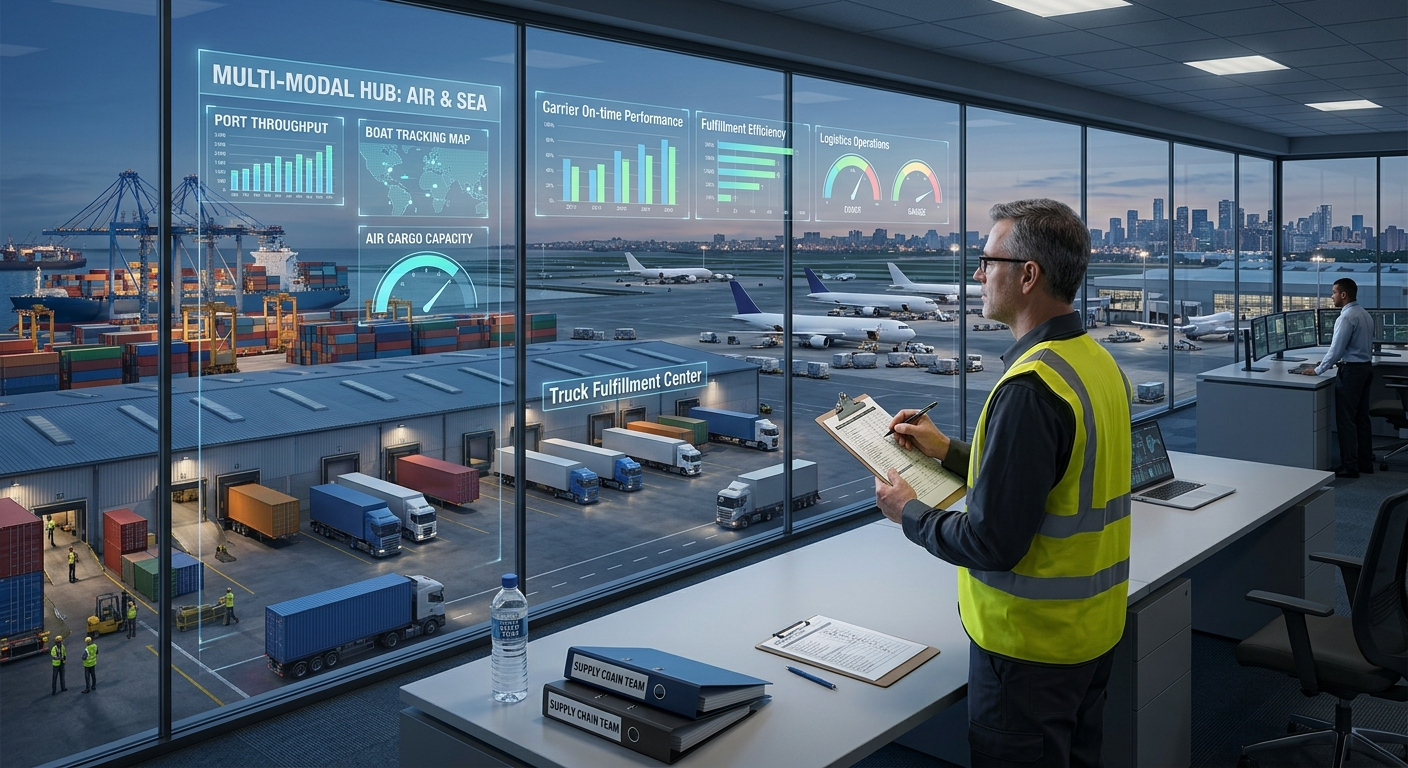

# Applied Statistics in Supply Chain

### Business Importance
Shipment performance directly drives service reliability, cost efficiency, and customer retention. Statistics turn delivery outcomes into measurable evidence, separating real operational patterns from random noise, and give leadership a defensible basis for prioritizing improvements across the fulfillment network.

### Business Problem
Logistics teams manage variability with static rules: fixed lead times, rigid safety stock, periodic manual reviews. These assumptions fail to capture interdependent delays, recurring damages, and carrier or route-level underperformance, producing avoidable service failures and costly expedites. Without a statistical foundation, organizations cannot reliably distinguish true performance gaps from noise, nor measure the impact of interventions.

### Project Objective
Apply a structured statistical framework, from descriptive analysis to inferential testing and distributional modeling to characterize shipment outcomes and identify the most significant drivers of delays, damages, and status failures. The result is a statistically grounded view of logistics risk that supports better forecasting, routing, and supplier decisions.

### Topics covered

1. Measures of Center and Variability
2. Normality Testing (Shapiro-Wilk, QQ-Plots, Histograms)
4. Confidence Intervals (for the Mean)
5. t-Tests (Paired, One-Sample, Two-Sample)
6. One-Proportion Z-Test
7. Poisson Tests for Rates (One-Sample & Two-Sample)
8. Bootstrapping & Monte Carlo Simulation
9. Chi-Square Tests (Goodness-of-Fit & Independence)
10. Binomial Distribution
11. Statistical Process Control (X-bar & R Control Charts)
12. One-Way ANOVA (with Tukey Post-Hoc)
13. A/B Testing (Two-Proportion Test & Two-Sample T-Test)
14. Difference-in-Differences (DiD) Causal Inference
15. Bayesian Inference (Beta-Binomial Conjugate Model)
16. Survival Analysis (Kaplan-Meier & Log-Rank Test)
17. Simple & Multiple Linear Regression
18. Logistic Regression vs. Random Forest (Classification)
19. Regression Diagnostics (Multicollinearity, Heteroskedasticity, Residual Analysis, Prediction Metrics)
20. Gradient Boosting (XGBoost) vs. Support Vector Machines (SVM)
21. Time Series Forecasting (SARIMA) & Exponential Smoothing (Holt-Winters)
22. Statistical Process Control (Attribute Charts, EWMA & Process Capability)

## Importing the dataset

In [ ]:
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("Supply_Chain_Logistics_Risk_Analytics")
    .getOrCreate()
)


# Read the full dataset from the bucket
raw_df = spark.read.parquet("gs://apex-analytics-prod-4821/operations/data/*.parquet")
raw_df.createOrReplaceTempView("shipments_raw")

# Select the columns needed for the analysis
df = spark.sql("""
    SELECT
        shipment_id,
        order_id,
        customer_id,
        product_id,
        supplier_id,
        carrier_id,
        route_id,
        origin_warehouse_id,
        destination_region,
        transport_mode,
        order_date,
        ship_date,
        promised_delivery_date,
        actual_delivery_date,
        order_quantity,
        unit_cost,
        shipping_cost,
        weight_kg,
        distance_km,
        lead_time_days,
        delay_days,
        damage_flag,
        shipment_status
    FROM shipments_raw
""")

## Dataset basic information

In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12586 entries, 0 to 12585
Data columns (total 23 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   shipment_id             12586 non-null  object 
 1   order_id                12586 non-null  object 
 2   customer_id             12586 non-null  object 
 3   product_id              12586 non-null  object 
 4   supplier_id             12586 non-null  object 
 5   carrier_id              12586 non-null  object 
 6   route_id                12586 non-null  object 
 7   origin_warehouse_id     12586 non-null  object 
 8   destination_region      12586 non-null  object 
 9   transport_mode          12586 non-null  object 
 10  order_date              12586 non-null  object 
 11  ship_date               12586 non-null  object 
 12  promised_delivery_date  12586 non-null  object 
 13  actual_delivery_date    12586 non-null  object 
 14  order_quantity          12586 non-null

| Column | Description |
| :--- | :--- |
| `shipment_id` | Unique identifier for each shipment. |
| `order_id` | Identifier of the order this shipment belongs to. |
| `customer_id` | Identifier of the customer receiving the shipment. |
| `product_id` | Identifier of the product being shipped. |
| `supplier_id` | Identifier of the supplier providing the goods. |
| `carrier_id` | Identifier of the logistics carrier handling the shipment. |
| `route_id` | Identifier of the predefined route used for the shipment. |
| `origin_warehouse_id` | Identifier of the warehouse the shipment departed from. |
| `destination_region` | Destination region of the shipment (NORTH, SOUTH, EAST, WEST, CENTRAL, INTERNATIONAL). |
| `transport_mode` | Mode of transportation used (ROAD, RAIL, AIR, SEA). |
| `order_date` | Date the order was placed. |
| `ship_date` | Date the shipment left the origin warehouse. |
| `promised_delivery_date` | Date the delivery was committed to the customer. |
| `actual_delivery_date` | Date the shipment was actually delivered. |
| `order_quantity` | Number of units in the shipment. |
| `unit_cost` | Cost per unit in USD. |
| `shipping_cost` | Total shipping cost in USD. |
| `weight_kg` | Total weight of the shipment in kilograms. |
| `distance_km` | Total distance covered by the shipment in kilometers. |
| `lead_time_days` | Actual number of days from `ship_date` to `actual_delivery_date`. |
| `delay_days` | Difference in days between `actual_delivery_date` and `promised_delivery_date` (positive = late, negative = early). |
| `damage_flag` | Binary flag: 1 = shipment arrived damaged, 0 = arrived in good condition. |
| `shipment_status` | Final status of the shipment: DELIVERED_ON_TIME, MINOR_DELAY, DELAYED, DAMAGED, or DAMAGED_AND_LATE. |

In [33]:
df

,shipment_id,order_id,customer_id,product_id,supplier_id,carrier_id,route_id,origin_warehouse_id,destination_region,transport_mode,...,is_tuesday,distance_band,group,treated,post,quarter,duration,event,segment,is_international
0,SHP0000001,ORD000001,CUS00370,PRD0046,SUP026,CAR010,RTE034,WH004,EAST,ROAD,...,False,251-400 km,B_standard,0,1,2024Q3,11,1,Domestic,0
1,SHP0000002,ORD000002,CUS00156,PRD0097,SUP010,CAR012,RTE029,WH010,SOUTH,ROAD,...,False,251-400 km,A_consolidated,0,0,2024Q1,5,1,Domestic,0
2,SHP0000003,ORD000003,CUS00494,PRD0049,SUP055,CAR008,RTE039,WH001,WEST,ROAD,...,False,251-400 km,B_standard,0,1,2024Q3,5,1,Domestic,0
3,SHP0000004,ORD000004,CUS00214,PRD0120,SUP015,CAR004,RTE027,WH015,INTERNATIONAL,RAIL,...,True,401-550 km,B_standard,1,0,2024Q1,9,1,International,1
4,SHP0000005,ORD000005,CUS00154,PRD0146,SUP048,CAR007,RTE012,WH003,INTERNATIONAL,AIR,...,True,>550 km,B_standard,1,1,2024Q3,10,1,International,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12581,SHP0012582,ORD012582,CUS00438,PRD0119,SUP006,CAR009,RTE016,WH004,WEST,ROAD,...,False,251-400 km,B_standard,0,1,2024Q3,12,1,Domestic,0
12582,SHP0012583,ORD012583,CUS00476,PRD0249,SUP019,CAR013,RTE019,WH003,CENTRAL,AIR,...,True,251-400 km,A_consolidated,0,0,2024Q1,14,1,Domestic,0
12583,SHP0012584,ORD012584,CUS00316,PRD0062,SUP047,CAR003,RTE032,WH015,EAST,AIR,...,False,251-400 km,A_consolidated,0,0,2024Q2,21,1,Domestic,0
12584,SHP0012585,ORD012585,CUS00029,PRD0140,SUP058,CAR015,RTE012,WH003,WEST,ROAD,...,False,251-400 km,B_standard,0,0,2024Q1,16,1,Domestic,0


In [4]:
df.isnull().sum()

shipment_id               0
order_id                  0
customer_id               0
product_id                0
supplier_id               0
carrier_id                0
route_id                  0
origin_warehouse_id       0
destination_region        0
transport_mode            0
order_date                0
ship_date                 0
promised_delivery_date    0
actual_delivery_date      0
order_quantity            0
unit_cost                 0
shipping_cost             0
weight_kg                 0
distance_km               0
lead_time_days            0
delay_days                0
damage_flag               0
shipment_status           0
dtype: int64

### **Business problem:** Inconsistent supplier lead times force planners to hold excess safety stock or risk stockouts. Comparing the center and spread of lead_time_days by supplier shows which suppliers are predictable and which are not.

             orders   mean  median   std  min  max   q1    q3  iqr    cv  \
supplier_id                                                                
SUP008          195   9.52     9.0  4.64    1   23  6.0  13.0  7.0  0.49   
SUP036          191   9.90    10.0  4.66    1   22  6.0  13.0  7.0  0.47   
SUP009          206  10.15    10.0  4.75    1   21  7.0  14.0  7.0  0.47   
SUP056          220   9.20     9.0  4.30    1   20  6.0  12.0  6.0  0.47   
SUP015          215   9.55    10.0  4.43    1   22  7.0  12.0  5.0  0.46   
SUP060          204   9.50     9.0  4.41    1   21  6.0  12.0  6.0  0.46   
SUP055          220   9.44     9.5  4.32    1   23  7.0  12.0  5.0  0.46   
SUP058          202  10.03    10.0  4.58    1   22  7.0  13.0  6.0  0.46   
SUP041          217   9.89    10.0  4.51    1   23  7.0  13.0  6.0  0.46   
SUP031          194  10.03    10.0  4.54    1   22  7.0  13.0  6.0  0.45   

             mean_median_gap  
supplier_id                   
SUP008                  0

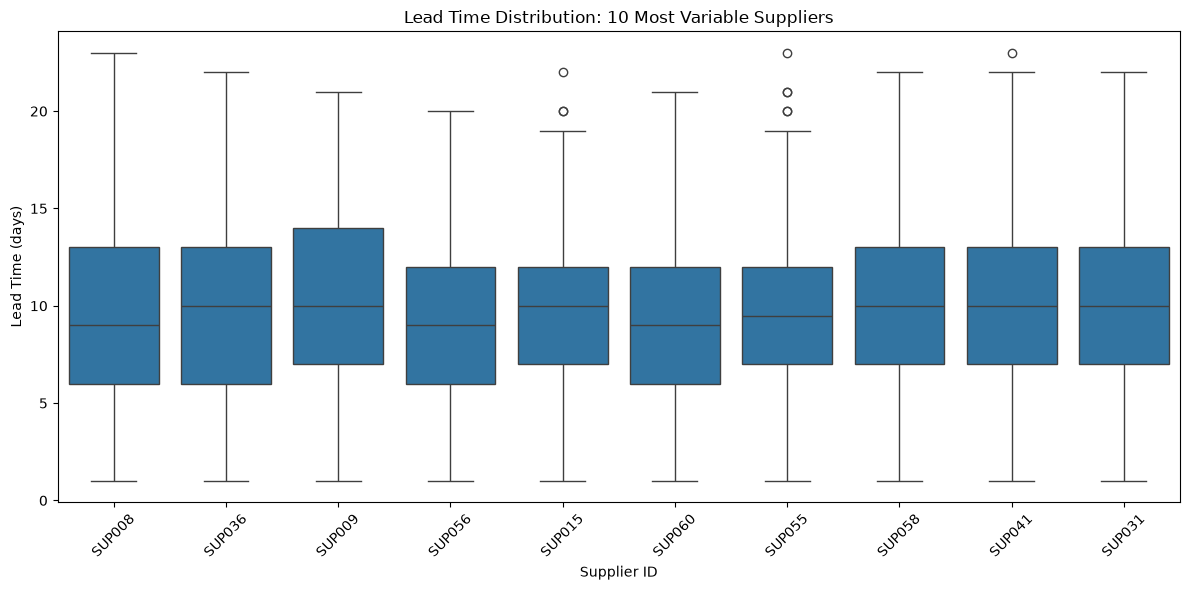

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Supplier-level lead time data
lead = (
    df[["supplier_id", "lead_time_days"]]
)

# Measures of center and variability by supplier
summary = (
    lead.groupby("supplier_id")["lead_time_days"]
        .agg(
            orders="count",
            mean="mean",
            median="median",
            std="std",
            min="min",
            max="max",
            q1=lambda x: x.quantile(0.25),
            q3=lambda x: x.quantile(0.75),
        )
        .assign(
            iqr=lambda d: d["q3"] - d["q1"],
            cv=lambda d: d["std"] / d["mean"],          # coefficient of variation
            mean_median_gap=lambda d: d["mean"] - d["median"],
        )
        .query("orders >= 30")
        .sort_values("cv", ascending=False)
)

print(summary.head(10).round(2))

# Compare the 10 least predictable suppliers
top_variable = summary.head(10).index
plt.figure(figsize=(12, 6))
sns.boxplot(
    data=lead[lead["supplier_id"].isin(top_variable)],
    x="supplier_id", y="lead_time_days", order=top_variable
)
plt.title("Lead Time Distribution: 10 Most Variable Suppliers")
plt.xlabel("Supplier ID")
plt.ylabel("Lead Time (days)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Conclusion and recommendation:** Suppliers with a high coefficient of variation or a large gap between mean and median have unstable lead times, often driven by occasional long delays rather than typical performance. Planning with average lead time alone understates the risk for these suppliers. Procurement should set supplier-specific safety stock based on lead time spread and open performance reviews with the highest-variability suppliers.

### **Business problem:** Safety stock formulas typically assume demand is normally distributed. If daily demand for a SKU is skewed, that assumption leads to stockouts or overstocking, so it must be tested before it is used.

Shapiro-Wilk W = 0.8155, p-value = 0.0000


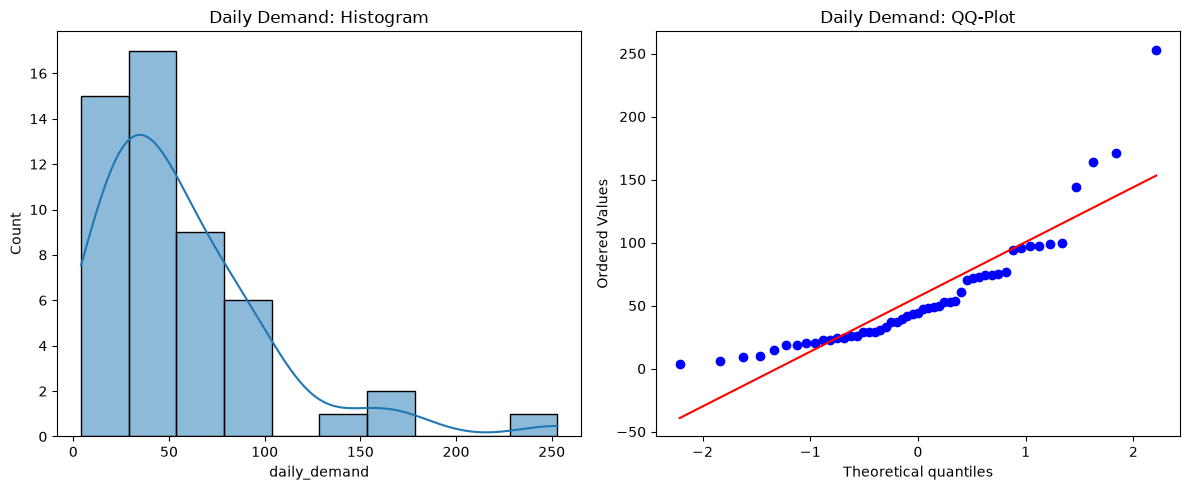

In [6]:
# Daily demand for the highest-volume SKU
demand_df = df.groupby(["product_id", "order_date"], as_index=False)["order_quantity"].sum()
demand_df = demand_df.rename(columns={"order_quantity": "daily_demand"})

top_product = demand_df.groupby("product_id")["daily_demand"].sum().idxmax()
demand = demand_df.loc[demand_df["product_id"] == top_product, "daily_demand"]

# Shapiro-Wilk test
w_stat, p_value = stats.shapiro(demand.sample(min(len(demand), 5000), random_state=42))
print(f"Shapiro-Wilk W = {w_stat:.4f}, p-value = {p_value:.4f}")

# Histogram and QQ-plot
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(demand, kde=True, ax=ax[0])
ax[0].set_title("Daily Demand: Histogram")
stats.probplot(demand, dist="norm", plot=ax[1])
ax[1].set_title("Daily Demand: QQ-Plot")
plt.tight_layout()
plt.show()

**Conclusion and recommendation:** A low Shapiro-Wilk p-value and tails that curve away from the QQ-plot line indicate that daily demand is not normally distributed. Using a normal-based safety stock formula would therefore underestimate the risk of demand spikes for this SKU. Planners should set reorder points using percentiles of the actual demand distribution instead.

### **Business problem:** Warehouses must meet a 72-hour order processing SLA. Because each site is measured on a sample of orders, confidence intervals show whether the true average is within the SLA or only appears to be.

In [7]:
SLA_HOURS = 72

df["order_date"] = pd.to_datetime(df["order_date"])
df["ship_date"] = pd.to_datetime(df["ship_date"])

df["processing_time_hours"] = (df["ship_date"] - df["order_date"]).dt.total_seconds() / 3600

proc = df[["origin_warehouse_id", "processing_time_hours"]].dropna()

def mean_ci(x):
    mean = x.mean()
    margin = stats.sem(x) * stats.t.ppf(0.975, df=len(x) - 1)
    return pd.Series({"mean_hours": mean, "ci_lower": mean - margin, "ci_upper": mean + margin})

ci_table = proc.groupby("origin_warehouse_id")["processing_time_hours"].apply(mean_ci).unstack()
ci_table["sla_status"] = np.where(ci_table["ci_lower"] > SLA_HOURS, "Breaching SLA",
                         np.where(ci_table["ci_upper"] < SLA_HOURS, "Within SLA", "Inconclusive"))

print(ci_table.round(2))

                     mean_hours  ci_lower  ci_upper  sla_status
origin_warehouse_id                                            
WH001                     61.19     58.50     63.88  Within SLA
WH002                     63.30     60.44     66.15  Within SLA
WH003                     58.68     55.89     61.47  Within SLA
WH004                     60.16     57.33     62.99  Within SLA
WH005                     60.95     58.23     63.66  Within SLA
WH006                     62.33     59.46     65.21  Within SLA
WH007                     60.87     58.09     63.65  Within SLA
WH008                     59.60     56.76     62.45  Within SLA
WH009                     60.11     57.29     62.94  Within SLA
WH010                     59.70     56.92     62.49  Within SLA
WH011                     57.31     54.53     60.10  Within SLA
WH012                     60.04     57.29     62.80  Within SLA
WH013                     60.14     57.41     62.87  Within SLA
WH014                     61.77     59.1

**Conclusion and recommendation:** Warehouses whose entire confidence interval sits above 72 hours are consistently breaching the SLA, while those whose interval straddles the threshold cannot yet be classified. This prevents corrective action on sites that may only look slow because of sampling noise. Operations should prioritize process improvement at the breaching warehouses and collect more data on the inconclusive ones.

### **Business Problem:** A distribution network must deliver orders on time while keeping processing and transportation costs under control, yet its delivery commitments are often set without testing them against actual performance. Management needs to know whether warehouses ship within the 2-day processing SLA, whether the delivery dates promised to customers reflect real transit performance, and whether premium transport modes such as air freight deliver a meaningful speed advantage over road.

#### Test 1: One-Sample t-Test

In [8]:
SLA_DAYS = 2
alpha = 0.05

df["processing_days"] = (df["ship_date"] - df["order_date"]).dt.days.astype(float)

t, p = stats.ttest_1samp(df["processing_days"], SLA_DAYS)
mean = df["processing_days"].mean()
ci = stats.t.interval(0.95, len(df) - 1, loc=mean, scale=stats.sem(df["processing_days"]))

print(f"Mean processing time = {mean:.2f} days vs SLA = {SLA_DAYS} days")
print(f"t = {t:.2f}, p-value = {p:.4g}, 95% CI = ({ci[0]:.2f}, {ci[1]:.2f})")
print("Reject H0: average differs from SLA" if p < alpha else "Fail to reject H0")

Mean processing time = 2.51 days vs SLA = 2 days
t = 33.75, p-value = 4.482e-239, 95% CI = (2.48, 2.54)
Reject H0: average differs from SLA


**Conclusion and recommendation:** Average processing time is 2.51 days, and the 95% confidence interval (2.48 to 2.54) sits entirely above the 2-day SLA, so the overshoot is statistically significant and not sampling noise. Operations should identify which warehouses or order types drive the extra half day and set a process improvement target to bring the mean within the SLA.

#### Test 2: Paired t-Test

In [9]:
import pandas as pd
from scipy import stats

# Make sure the date columns are datetime
date_cols = ["order_date", "ship_date", "promised_delivery_date", "actual_delivery_date"]
for c in date_cols:
    df[c] = pd.to_datetime(df[c], errors="coerce")

df["processing_days"]    = (df["ship_date"] - df["order_date"]).dt.days.astype(float)
df["promised_lead_days"] = (df["promised_delivery_date"] - df["order_date"]).dt.days.astype(float)
df["actual_lead_days"]   = (df["actual_delivery_date"] - df["order_date"]).dt.days.astype(float)

t, p = stats.ttest_rel(df["actual_lead_days"], df["promised_lead_days"])

diff = df["actual_lead_days"] - df["promised_lead_days"]

print(f"Promised lead time = {df['promised_lead_days'].mean():.2f} days | Actual = {df['actual_lead_days'].mean():.2f} days")
print(f"Mean difference = {diff.mean():.2f} days | t = {t:.2f}, p-value = {p:.4g}")
print(f"Shipments delivered after the promised date: {(diff > 0).mean():.1%}")

Promised lead time = 14.81 days | Actual = 12.59 days
Mean difference = -2.22 days | t = -121.23, p-value = 0
Shipments delivered after the promised date: 9.0%


**Conclusion and recommendation:** Shipments arrive on average 2.22 days earlier than promised, and only 9.0% are delivered late, a highly significant gap. This points to systematically padded delivery promises, which protects on-time metrics but may make the company less competitive on quoted delivery times. Planning should tighten promise dates by segment (for example by transport mode or region) while keeping the late rate within an acceptable limit.

#### Test 3: Two-Sample t-Test (Welch)

In [10]:
air  = df.loc[df["transport_mode"] == "AIR",  "lead_time_days"]
road = df.loc[df["transport_mode"] == "ROAD", "lead_time_days"]

t, p = stats.ttest_ind(air, road, equal_var=False)
cohen_d = (air.mean() - road.mean()) / np.sqrt((air.var() + road.var()) / 2)

print(f"Lead time: AIR = {air.mean():.2f} days | ROAD = {road.mean():.2f} days | diff = {air.mean() - road.mean():.2f}")
print(f"t = {t:.2f}, p-value = {p:.4g}, Cohen's d = {cohen_d:.2f}")

print(df.groupby("transport_mode")[["lead_time_days", "shipping_cost"]].mean().round(2))

Lead time: AIR = 9.68 days | ROAD = 10.50 days | diff = -0.82
t = -7.52, p-value = 6.277e-14, Cohen's d = -0.19
                lead_time_days  shipping_cost
transport_mode                               
AIR                       9.68          93.34
RAIL                     10.10          93.19
ROAD                     10.50          94.90
SEA                       9.82          92.26


**Conclusion and recommendation:** Air is statistically faster than road by about 0.82 days (p < 0.001), but the effect size is small (Cohen’s d = -0.19), and average shipping cost is nearly identical across modes (about USD 93 to USD 95). Because the speed advantage is marginal, the data does not show that air freight delivers a meaningful service premium, so mode selection rules and carrier contracts should be reviewed before assigning more volume to air.

### **Business problem:** Shipment damage drives claims, returns, and customer complaints. The company’s quality target is a damage rate of no more than 10%. Is the true damage rate above that limit, and where is it concentrated?

In [11]:
import numpy as np
import pandas as pd
from scipy import stats

# Maximum acceptable damage rate
TARGET = 0.10          
alpha = 0.05

n = len(df)
x = int(df["damage_flag"].sum())
p_hat = x / n

# One-proportion z-test (H0: p = 10%  vs  H1: p > 10%)
se = np.sqrt(TARGET * (1 - TARGET) / n)
z = (p_hat - TARGET) / se
p_value = 1 - stats.norm.cdf(z)

# 95% confidence interval for the true damage rate
se_ci = np.sqrt(p_hat * (1 - p_hat) / n)
ci = (p_hat - 1.96 * se_ci, p_hat + 1.96 * se_ci)

print(f"Damaged shipments: {x:,} of {n:,} ({p_hat:.2%}) vs target {TARGET:.0%}")
print(f"z = {z:.2f}, p-value = {p_value:.4g}, 95% CI = ({ci[0]:.2%}, {ci[1]:.2%})")
print("Reject H0: damage rate exceeds target" if p_value < alpha else "Fail to reject H0")

# Where is the problem concentrated?
by_region = (df.groupby("destination_region")["damage_flag"]
               .agg(shipments="count", damage_rate="mean")
               .sort_values("damage_rate", ascending=False)
               .round(4))
print(by_region)

Damaged shipments: 1,478 of 12,586 (11.74%) vs target 10%
z = 6.52, p-value = 3.542e-11, 95% CI = (11.18%, 12.31%)
Reject H0: damage rate exceeds target
                    shipments  damage_rate
destination_region                        
INTERNATIONAL            2287       0.2965
SOUTH                    2012       0.0984
CENTRAL                  1978       0.0910
EAST                     2027       0.0789
WEST                     2036       0.0751
NORTH                    2246       0.0485


**Conclusion and recommendation:** The overall damage rate is 11.74% (95% CI: 11.18% to 12.31%), which is significantly above the 10% target (z = 6.52, p < 0.001). The problem is not evenly spread: international shipments have a damage rate of about 29.6%, versus roughly 5% to 10% for domestic regions. Management should prioritize packaging standards and carrier handling requirements for international lanes, since fixing that segment alone would bring the network close to or below the target.

### **Business problem:** Late deliveries are the most frequent service failure in the network, and they are counted as events over time or exposure, which makes them a natural fit for Poisson models. Management needs to know whether the daily volume of late deliveries exceeds the operational target, and whether late deliveries are concentrated on specific ship days, such as Tuesday, so that staffing and carrier pickup schedules can be adjusted.

#### One-Sample Poisson Test

In [12]:
import numpy as np
import pandas as pd
from scipy import stats

df["ship_date"] = pd.to_datetime(df["ship_date"])
df["actual_delivery_date"] = pd.to_datetime(df["actual_delivery_date"])
df["is_late"] = (df["delay_days"] > 0).astype(int)

alpha = 0.05

TARGET_PER_DAY = 2.5

# Daily count of late deliveries, including days with zero events
days = pd.date_range(df["actual_delivery_date"].min(), df["actual_delivery_date"].max())
daily_late = df.groupby("actual_delivery_date")["is_late"].sum().reindex(days, fill_value=0)

total_late, n_days = int(daily_late.sum()), len(daily_late)
rate = total_late / n_days

# Exact test: P(X >= observed) when expected count = target * days
p_value = stats.poisson.sf(total_late - 1, TARGET_PER_DAY * n_days)

# 95% exact (Garwood) confidence interval for the daily rate
lo = stats.chi2.ppf(0.025, 2 * total_late) / 2 / n_days
hi = stats.chi2.ppf(0.975, 2 * (total_late + 1)) / 2 / n_days

print(f"Late deliveries: {total_late:,} over {n_days} days = {rate:.2f} per day (target {TARGET_PER_DAY})")
print(f"p-value = {p_value:.4g} | 95% CI = ({lo:.2f}, {hi:.2f}) per day")
print(f"Variance/mean ratio = {daily_late.var() / daily_late.mean():.2f} (close to 1 supports the Poisson assumption)")
print("Reject H0: late-delivery rate exceeds target" if p_value < alpha else "Fail to reject H0")

Late deliveries: 1,135 over 385 days = 2.95 per day (target 2.5)
p-value = 3.419e-08 | 95% CI = (2.78, 3.12) per day
Variance/mean ratio = 1.17 (close to 1 supports the Poisson assumption)
Reject H0: late-delivery rate exceeds target


**Conclusion and recommendation:** The network averages 2.95 late deliveries per day (95% CI: 2.78 to 3.12), significantly above the 2.5 per day target (p < 0.001), and the variance-to-mean ratio of 1.17 supports using a Poisson model. This means the service shortfall is a sustained pattern and not random daily fluctuation. Operations should either set a corrective action plan to reduce the daily late volume or revisit whether the 2.5 target is realistic for current demand.

#### Two-Sample Poisson Test

In [13]:
import numpy as np
import pandas as pd
from scipy import stats

df["ship_date"] = pd.to_datetime(df["ship_date"])
df["actual_delivery_date"] = pd.to_datetime(df["actual_delivery_date"])
df["is_late"] = (df["delay_days"] > 0).astype(int)

alpha = 0.05

df["is_tuesday"] = df["ship_date"].dt.day_name() == "Tuesday"

g = df.groupby("is_tuesday")["is_late"].agg(late="sum", shipments="count")

k1, n1 = g.loc[True,  "late"], g.loc[True,  "shipments"]   # Tuesday
k2, n2 = g.loc[False, "late"], g.loc[False, "shipments"]   # Other days

# Compares late deliveries per shipment (exposure = shipments)
res = stats.poisson_means_test(k1, n1, k2, n2, alternative="greater")

print(f"Tuesday:    {k1} late / {n1:,} shipments = {k1/n1*100:.2f} per 100")
print(f"Other days: {k2} late / {n2:,} shipments = {k2/n2*100:.2f} per 100")
print(f"Rate ratio = {(k1/n1)/(k2/n2):.2f} | p-value = {res.pvalue:.4g}")
print("Reject H0: Tuesday rate is higher" if res.pvalue < alpha else "Fail to reject H0")

Tuesday:    205 late / 1,770 shipments = 11.58 per 100
Other days: 930 late / 10,816 shipments = 8.60 per 100
Rate ratio = 1.35 | p-value = 8.966e-05
Reject H0: Tuesday rate is higher


**Conclusion and recommendation:** Shipments dispatched on Tuesday are late at a rate of 11.58 per 100 versus 8.60 per 100 on other days, a rate ratio of 1.35 that is statistically significant (p < 0.001). Since shipment volume is similar across weekdays, the gap points to a process or capacity issue specific to Tuesday dispatch, such as carrier pickup schedules or warehouse workload after Monday order accumulation. The team should review Tuesday operations, starting with carrier pickup windows and staffing levels, and track whether the late rate converges with other days.

### **Business problem:** Inventory planners set reorder points using average demand and average lead time, but both are variable and neither follows a clean theoretical distribution. Management needs to know how reliable the lead time estimates are, and how much stock is needed to avoid stockouts while waiting for replenishment.

#### Bootstrapping

In [14]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)

df["order_date"] = pd.to_datetime(df["order_date"])

# Focus on the highest-volume warehouse
wh = df["origin_warehouse_id"].value_counts().index[0]
sub = df[df["origin_warehouse_id"] == wh]

lead_times = sub["lead_time_days"].to_numpy()

# Daily demand, including days with no orders
all_days = pd.date_range(df["order_date"].min(), df["order_date"].max())
daily_demand = (sub.groupby("order_date")["order_quantity"].sum()
                   .reindex(all_days, fill_value=0).to_numpy())

B = 10_000
boot_mean = np.empty(B)
boot_p95 = np.empty(B)

for i in range(B):
    s = rng.choice(lead_times, size=len(lead_times), replace=True)
    boot_mean[i] = s.mean()
    boot_p95[i] = np.percentile(s, 95)

print(f"Warehouse {wh} | {len(lead_times)} shipments")
print(f"Mean lead time: {lead_times.mean():.2f} days | 95% CI = {np.percentile(boot_mean, [2.5, 97.5]).round(2)}")
print(f"95th pct lead time: {np.percentile(lead_times, 95):.1f} days | 95% CI = {np.percentile(boot_p95, [2.5, 97.5]).round(2)}")

Warehouse WH001 | 897 shipments
Mean lead time: 9.89 days | 95% CI = [ 9.61 10.17]
95th pct lead time: 17.0 days | 95% CI = [16. 17.]


**Conclusion and recommendation:** For warehouse WH001, mean lead time is 9.89 days (95% bootstrap CI: 9.61 to 10.17), while the 95th percentile is 17 days (CI: 16 to 17), so the worst-case lead time is nearly 7 days longer than the average. Bootstrapping works here without assuming normality, and the narrow intervals show that these estimates are stable. Planners should base replenishment buffers on the 95th percentile lead time, not on the average.

#### Monte Carlo Simulation

In [15]:
N = 100_000

# Simulate a lead time, then the demand accumulated over those days
sim_lt = rng.choice(lead_times, size=N, replace=True)
sim_demand = np.array([rng.choice(daily_demand, size=lt, replace=True).sum() for lt in sim_lt])

# Average demand x average lead time
naive_rop = daily_demand.mean() * lead_times.mean()

# # Reorder point for 95% service level
rop_95 = np.percentile(sim_demand, 95)                 
stockout_naive = (sim_demand > naive_rop).mean()

print(f"Average demand during lead time: {sim_demand.mean():,.0f} units")
print(f"Naive reorder point (avg x avg): {naive_rop:,.0f} units -> stockout probability = {stockout_naive:.1%}")
print(f"Reorder point for 95% service level: {rop_95:,.0f} units (+{rop_95 - naive_rop:,.0f} units of safety stock)")

Average demand during lead time: 1,011 units
Naive reorder point (avg x avg): 1,011 units -> stockout probability = 47.5%
Reorder point for 95% service level: 1,897 units (+886 units of safety stock)


**Conclusion and recommendation:** Using the average-based reorder point of about 1,011 units leaves the warehouse exposed to a 47.5% probability of stocking out during replenishment, because it ignores the variability in both demand and lead time. Reaching a 95% service level requires a reorder point of about 1,897 units, roughly 886 units of additional safety stock. The team should adopt simulation-based reorder points for high-volume SKUs and weigh the extra holding cost against the cost of lost sales.

### **Business problem:** Logistics managers need to confirm that shipment volume is spread evenly across carriers, so the network does not depend too heavily on any one of them. They also need to understand whether damage is a random event or is linked to shipment characteristics such as distance. Both questions involve categorical data, which makes chi-square tests the right tool.

#### Goodness-of-Fit

In [16]:
import numpy as np
import pandas as pd
from scipy import stats

alpha = 0.05

observed = df["carrier_id"].value_counts().sort_index()
expected = np.full(len(observed), observed.sum() / len(observed))      # equal share per carrier

chi2, p = stats.chisquare(observed, f_exp=expected)

print(f"Carriers: {len(observed)} | expected shipments per carrier: {expected[0]:.0f}")
print(f"Chi-square = {chi2:.2f}, df = {len(observed) - 1}, p-value = {p:.4f}")
print(f"Largest carrier share: {observed.max() / observed.sum():.1%} ({observed.idxmax()}) | smallest: {observed.min() / observed.sum():.1%} ({observed.idxmin()})")
print("Reject H0: volume is NOT evenly distributed" if p < alpha else "Fail to reject H0: volume is evenly distributed")

Carriers: 20 | expected shipments per carrier: 629
Chi-square = 11.99, df = 19, p-value = 0.8860
Largest carrier share: 5.3% (CAR001) | smallest: 4.7% (CAR003)
Fail to reject H0: volume is evenly distributed


**Conclusion and recommendation:** Shipment volume is evenly distributed across the 20 carriers (chi-square = 11.99, p = 0.886), with shares ranging only from 4.7% to 5.3%. This means the network has no concentration risk, so losing any single carrier would affect about 5% of volume. Procurement can therefore compare carriers on performance and cost without worrying about dependency, and should only rebalance volume if quality differences justify it.

#### Test of Independence

In [17]:
df["distance_band"] = pd.cut(df["distance_km"], bins=[0, 250, 400, 550, np.inf],
                             labels=["<=250 km", "251-400 km", "401-550 km", ">550 km"])

ct = pd.crosstab(df["distance_band"], df["damage_flag"])
chi2, p, dof, exp = stats.chi2_contingency(ct)
cramers_v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))

print(f"Chi-square = {chi2:.1f}, df = {dof}, p-value = {p:.4g}, Cramer's V = {cramers_v:.2f}")
print("Minimum expected count:", exp.min().round(1))
print((df.groupby("distance_band", observed=True)["damage_flag"].mean() * 100).round(1).rename("damage rate (%)"))

# Which cells drive the result?
resid = pd.DataFrame((ct.values - exp) / np.sqrt(exp), index=ct.index, columns=["No damage", "Damaged"])
print(resid.round(1))

Chi-square = 1169.4, df = 3, p-value = 3.216e-253, Cramer's V = 0.30
Minimum expected count: 205.7
distance_band
<=250 km       3.7
251-400 km     6.2
401-550 km    12.8
>550 km       34.7
Name: damage rate (%), dtype: float64
               No damage  Damaged
distance_band                    
<=250 km             3.8    -10.4
251-400 km           4.2    -11.5
401-550 km          -0.7      1.9
>550 km            -10.2     28.0


**Conclusion and recommendation:** Damage is strongly dependent on shipping distance (chi-square = 1,169, p < 0.001, Cramér’s V = 0.30), with damage rates rising from 3.7% for shipments under 250 km to 34.7% for those over 550 km. The standardized residuals show that long-distance shipments are the main driver, with far more damaged shipments than expected under independence. Management should apply stronger packaging and handling requirements, or carrier selection rules, to shipments over 550 km, since that segment concentrates most of the damage risk.

### **Business problem:** Dispatch teams ship in batches and need a rule to decide when a batch has an unusual number of late deliveries, versus ordinary random variation. Management also wants to know whether any carrier’s late rate is genuinely worse than the network average, or whether apparent differences are just chance. Each shipment is either late or on time, so the binomial distribution models both questions.

#### Binomial model for a dispatch batch

In [18]:
import numpy as np
import pandas as pd
from scipy import stats

df["is_late"] = (df["delay_days"] > 0).astype(int)

alpha = 0.05
p_late = df["is_late"].mean()
print(f"Network late-delivery rate: {p_late:.2%} ({df['is_late'].sum():,} of {len(df):,})")

# Shipments per dispatch batch
n = 20
X = stats.binom(n, p_late)

pmf = pd.DataFrame({"late_shipments": range(0, 7)})
pmf["P(X = k)"] = X.pmf(pmf["late_shipments"]).round(4)
pmf["P(X >= k)"] = X.sf(pmf["late_shipments"] - 1).round(4)

print(f"Batch of {n}: expected late = {X.mean():.2f}, std = {X.std():.2f}")
print(pmf)

alert_k = int(X.isf(0.05)) + 1           # smallest k with P(X >= k) <= 5%
print(f"Alert threshold: {alert_k}+ late shipments in a batch of {n} occurs by chance only {X.sf(alert_k - 1):.1%} of the time")

Network late-delivery rate: 9.02% (1,135 of 12,586)
Batch of 20: expected late = 1.80, std = 1.28
   late_shipments  P(X = k)  P(X >= k)
0               0    0.1510     1.0000
1               1    0.2994     0.8490
2               2    0.2820     0.5495
3               3    0.1677     0.2676
4               4    0.0706     0.0999
5               5    0.0224     0.0293
6               6    0.0056     0.0069
Alert threshold: 5+ late shipments in a batch of 20 occurs by chance only 2.9% of the time


**Conclusion and recommendation:** With a 9.02% late rate, a batch of 20 shipments is expected to contain 1.8 late deliveries (standard deviation 1.28), and 5 or more late shipments would occur by chance only 2.9% of the time. This gives a statistical definition of an abnormal batch, which separates normal variation from a real operational problem. Dispatch supervisors should use “5+ late in a batch of 20” as an automatic alert for investigation.

#### Exact binomial test by carrier

In [19]:
rows = []
for carrier, g in df.groupby("carrier_id"):
    k, m = int(g["is_late"].sum()), len(g)
    test = stats.binomtest(k, m, p_late, alternative="greater")
    rows.append({"carrier_id": carrier, "shipments": m, "late": k,
                 "late_rate": k / m, "p_value": test.pvalue})

carriers = pd.DataFrame(rows).sort_values("p_value")
carriers["bonferroni_p"] = (carriers["p_value"] * len(carriers)).clip(upper=1)

print(carriers.head(5).round(4).to_string(index=False))
print(f"Significant at raw alpha {alpha}: {(carriers['p_value'] < alpha).sum()} | after Bonferroni correction: {(carriers['bonferroni_p'] < alpha).sum()}")

carrier_id  shipments  late  late_rate  p_value  bonferroni_p
    CAR017        625    71     0.1136   0.0271        0.5420
    CAR020        619    69     0.1115   0.0407        0.8149
    CAR006        616    60     0.0974   0.2848        1.0000
    CAR012        619    60     0.0969   0.2980        1.0000
    CAR016        626    60     0.0958   0.3297        1.0000
Significant at raw alpha 0.05: 2 | after Bonferroni correction: 0


**Conclusion and recommendation:** Two carriers (CAR017 at 11.4% and CAR020 at 11.2%) look worse than the 9.0% network average when tested individually, but neither remains significant after correcting for testing 20 carriers at once (adjusted p = 0.54 and 0.81). This means the differences are consistent with random variation, so there is no statistical basis for penalizing any carrier yet. The team should keep monitoring these two carriers with the batch alert rule and collect more shipments before taking contractual action.

### **Business problem:** Order processing time (order date to ship date) is a core service metric with a 2-day SLA. Management needs to know whether this process is stable and predictable, or whether special causes such as staffing gaps, system issues, or demand spikes are pushing it out of control. Distinguishing normal variation from real signals prevents both overreacting to noise and missing true problems.

Subgroups: 365 (n = 5)
X-bar chart: CL = 2.45, UCL = 4.65, LCL = 0.25
R chart:     CL = 3.81, UCL = 8.06, LCL = 0.00
Out-of-control points: X-bar = 0, R = 0
Longest run on one side of the center line: 8 points
Process center = 2.45 days vs SLA = 2 days
Share of shipments above SLA: 50.1%


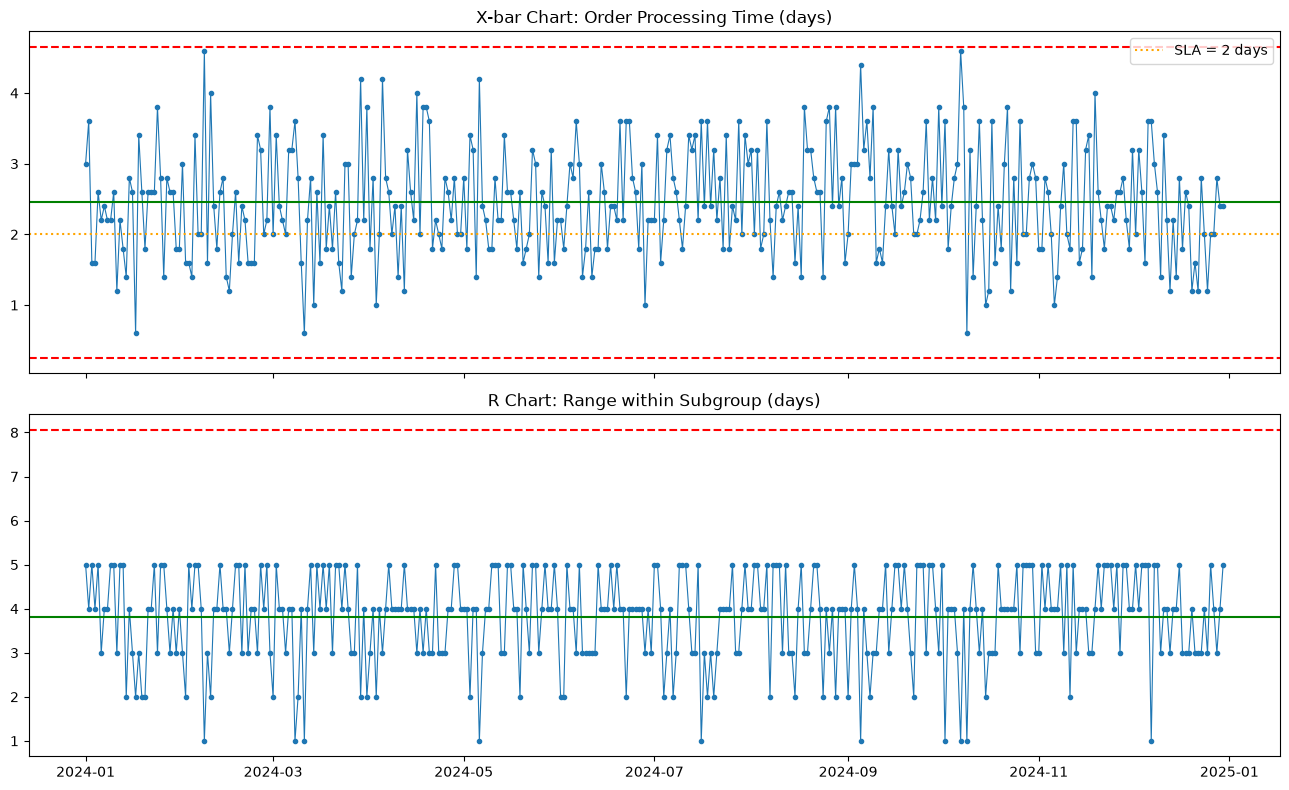

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df["order_date"] = pd.to_datetime(df["order_date"])
df["ship_date"] = pd.to_datetime(df["ship_date"])
df["processing_days"] = (df["ship_date"] - df["order_date"]).dt.days

# Rational subgroups: first 5 shipments of each order day
n = 5
sub = (df.sort_values(["order_date", "shipment_id"])
         .groupby("order_date")
         .filter(lambda g: len(g) >= n)
         .groupby("order_date")
         .head(n))

chart = sub.groupby("order_date")["processing_days"].agg(xbar="mean", r=lambda x: x.max() - x.min())

# Control chart constants for subgroup size n = 5
A2, D3, D4 = 0.577, 0.0, 2.114

xbar_bar, r_bar = chart["xbar"].mean(), chart["r"].mean()
ucl_x, lcl_x = xbar_bar + A2 * r_bar, xbar_bar - A2 * r_bar
ucl_r, lcl_r = D4 * r_bar, D3 * r_bar

print(f"Subgroups: {len(chart)} (n = {n})")
print(f"X-bar chart: CL = {xbar_bar:.2f}, UCL = {ucl_x:.2f}, LCL = {lcl_x:.2f}")
print(f"R chart:     CL = {r_bar:.2f}, UCL = {ucl_r:.2f}, LCL = {lcl_r:.2f}")

SLA_DAYS = 2

out_x = chart[(chart["xbar"] > ucl_x) | (chart["xbar"] < lcl_x)]
out_r = chart[(chart["r"] > ucl_r) | (chart["r"] < lcl_r)]
print(f"Out-of-control points: X-bar = {len(out_x)}, R = {len(out_r)}")

# Run rule: 8 consecutive points on the same side of the center line
side = np.sign(chart["xbar"] - xbar_bar)
run_id = (side != side.shift()).cumsum()
print(f"Longest run on one side of the center line: {side.groupby(run_id).size().max()} points")

# Stable does not mean compliant: how much of the process exceeds the SLA?
print(f"Process center = {xbar_bar:.2f} days vs SLA = {SLA_DAYS} days")
print(f"Share of shipments above SLA: {(df['processing_days'] > SLA_DAYS).mean():.1%}")

fig, ax = plt.subplots(2, 1, figsize=(13, 8), sharex=True)

ax[0].plot(chart.index, chart["xbar"], marker="o", markersize=3, linewidth=0.8)
ax[0].axhline(xbar_bar, color="green")
ax[0].axhline(ucl_x, color="red", linestyle="--")
ax[0].axhline(lcl_x, color="red", linestyle="--")
ax[0].axhline(SLA_DAYS, color="orange", linestyle=":", label=f"SLA = {SLA_DAYS} days")
ax[0].set_title("X-bar Chart: Order Processing Time (days)")
ax[0].legend()

ax[1].plot(chart.index, chart["r"], marker="o", markersize=3, linewidth=0.8)
ax[1].axhline(r_bar, color="green")
ax[1].axhline(ucl_r, color="red", linestyle="--")
ax[1].set_title("R Chart: Range within Subgroup (days)")

plt.tight_layout()
plt.show()

**Conclusion and recommendation:** Across 365 daily subgroups, no points fall outside the X-bar limits (0.25 to 4.65 days) or the R chart limit (8.06 days), so the process is statistically stable with no evidence of special causes. However, stability does not mean compliance: the process is centered at 2.45 days and 50.1% of shipments exceed the 2-day SLA, because the variation is built into the process itself. Management should stop searching for one-off causes and instead redesign the process (capacity, cut-off times, or workflow) to shift the center and reduce the spread, then use these control limits to confirm the improvement.

### **Business problem:** Shipping cost is one of the largest controllable expenses in logistics, and the network serves six destination regions. Management needs to know whether the average cost per shipment truly differs by region, and if so, which specific regions are more expensive, so pricing, carrier negotiations, and cost-reduction efforts can be directed to the right lanes.

In [21]:
import numpy as np
import pandas as pd
from scipy import stats

alpha = 0.05

summary = (df.groupby("destination_region")["shipping_cost"]
             .agg(shipments="count", mean="mean", std="std")
             .sort_values("mean", ascending=False).round(2))
print(summary)

groups = {name: g["shipping_cost"].values for name, g in df.groupby("destination_region")}

# Assumption check: equal variances
lev_stat, lev_p = stats.levene(*groups.values())
print(f"Levene test: W = {lev_stat:.2f}, p = {lev_p:.4g}")

# One-way ANOVA
F, p = stats.f_oneway(*groups.values())
k, N = len(groups), len(df)
eta_sq = (F * (k - 1)) / (F * (k - 1) + (N - k))
print(f"ANOVA: F = {F:.2f}, p = {p:.4g}, eta-squared = {eta_sq:.3f}")

# Robustness check (non-parametric alternative)
h, p_kw = stats.kruskal(*groups.values())
print(f"Kruskal-Wallis: H = {h:.1f}, p = {p_kw:.4g}")

names = list(groups.keys())
tukey = stats.tukey_hsd(*groups.values())

rows = []
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        rows.append({"group_1": names[i], "group_2": names[j],
                     "mean_diff": tukey.statistic[i, j],
                     "p_adj": tukey.pvalue[i, j]})

pairs = pd.DataFrame(rows)
pairs["significant"] = pairs["p_adj"] < alpha
print(pairs.sort_values("p_adj").round(4).to_string(index=False))
print(f"Significant pairs: {pairs['significant'].sum()} of {len(pairs)}")

                    shipments    mean    std
destination_region                          
INTERNATIONAL            2287  110.68  39.14
CENTRAL                  1978   92.21  35.90
SOUTH                    2012   91.75  35.34
WEST                     2036   90.55  35.03
EAST                     2027   88.82  34.29
NORTH                    2246   86.12  34.12
Levene test: W = 10.05, p = 1.285e-09
ANOVA: F = 136.10, p = 5.337e-141, eta-squared = 0.051
Kruskal-Wallis: H = 550.9, p = 8.171e-117
      group_1       group_2  mean_diff  p_adj  significant
      CENTRAL INTERNATIONAL   -18.4632 0.0000         True
         EAST INTERNATIONAL   -21.8515 0.0000         True
INTERNATIONAL         SOUTH    18.9252 0.0000         True
INTERNATIONAL         NORTH    24.5602 0.0000         True
INTERNATIONAL          WEST    20.1239 0.0000         True
      CENTRAL         NORTH     6.0971 0.0000         True
        NORTH         SOUTH    -5.6350 0.0000         True
        NORTH          WEST    -4

**Conclusion and recommendation:** Average shipping cost differs significantly by region (F = 136.10, p < 0.001, eta-squared = 0.051), and Tukey’s test shows that international shipments average USD 110.68, about USD 18 to USD 25 more than every domestic region, which is roughly 23% above the domestic average of $89.80. Differences among domestic regions are small (a few dollars), so the real cost driver is international versus domestic, not geography within the country. Procurement should focus cost-reduction efforts and carrier renegotiation on international lanes first, since that is where the savings potential is concentrated.

### **Business problem:** The company is considering a consolidation policy that groups small orders into larger shipments. Management wants evidence on whether consolidated orders (Group A, more than 40 units) perform better than standard orders (Group B) in damage rate and transit lead time. The comparison uses existing shipments, so it is a natural experiment and not a randomized one, and the test is repeated on domestic shipments only to check that the result is not driven by shipment mix.

In [22]:
import numpy as np
import pandas as pd
from scipy import stats

alpha = 0.05

# Group A: consolidated orders (> 40 units) | Group B: standard orders
df["group"] = np.where(df["order_quantity"] > 40, "A_consolidated", "B_standard")

def ab_test(data, label):
    a = data[data["group"] == "A_consolidated"]
    b = data[data["group"] == "B_standard"]

    # Two-proportion z-test: damage rate
    x1, n1, x2, n2 = a["damage_flag"].sum(), len(a), b["damage_flag"].sum(), len(b)
    p1, p2 = x1 / n1, x2 / n2
    p_pool = (x1 + x2) / (n1 + n2)
    z = (p1 - p2) / np.sqrt(p_pool * (1 - p_pool) * (1 / n1 + 1 / n2))
    p_z = 2 * (1 - stats.norm.cdf(abs(z)))
    se = np.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)
    ci = (p1 - p2 - 1.96 * se, p1 - p2 + 1.96 * se)

    # Two-sample (Welch) t-test: transit lead time
    t, p_t = stats.ttest_ind(a["lead_time_days"], b["lead_time_days"], equal_var=False)

    print(f"--- {label} (A = {n1:,}, B = {n2:,}) ---")
    print(f"Damage rate: A = {p1:.2%} vs B = {p2:.2%} | diff = {p1 - p2:+.2%} "
          f"(95% CI {ci[0]:+.2%} to {ci[1]:+.2%}) | z = {z:.2f}, p = {p_z:.4g}")
    print(f"Lead time:   A = {a['lead_time_days'].mean():.2f} vs B = {b['lead_time_days'].mean():.2f} days "
          f"| diff = {a['lead_time_days'].mean() - b['lead_time_days'].mean():+.2f} | t = {t:.2f}, p = {p_t:.4g}\n")

ab_test(df, "All shipments")

# Confounding check: international shipments have smaller orders and higher damage
ab_test(df[df["destination_region"] != "INTERNATIONAL"], "Domestic shipments only")

--- All shipments (A = 4,761, B = 7,825) ---
Damage rate: A = 8.02% vs B = 14.01% | diff = -5.98% (95% CI -7.07% to -4.89%) | z = -10.11, p = 0
Lead time:   A = 9.13 vs B = 10.66 days | diff = -1.53 | t = -19.70, p = 8.136e-85

--- Domestic shipments only (A = 4,308, B = 5,991) ---
Damage rate: A = 6.27% vs B = 8.85% | diff = -2.58% (95% CI -3.60% to -1.56%) | z = -4.82, p = 1.409e-06
Lead time:   A = 8.86 vs B = 10.04 days | diff = -1.18 | t = -14.20, p = 2.565e-45



**Conclusion and recommendation:** Consolidated orders show a lower damage rate (8.02% vs 14.01%, a 5.98 point difference) and a shorter lead time (9.13 vs 10.66 days), both highly significant. The gap shrinks but remains significant when only domestic shipments are compared (damage 6.27% vs 8.85%, lead time 1.18 days faster), which shows that part of the raw difference came from international shipments being smaller and more damage-prone. The company should pilot consolidation on domestic lanes with random assignment, since the adjusted estimate of about 2.6 points of damage reduction is the more reliable expectation.

### **Business problem:** International shipments have the highest damage rate in the network (about 29.6%). Suppose a new international packaging standard was introduced on July 1, 2024, and management needs to know whether it actually reduced damage. A simple before-and-after comparison is misleading, because damage can change over time for reasons unrelated to the policy. DiD compares the change in international shipments (treated) against the change in domestic shipments (control) over the same period.

In [23]:
import numpy as np
import pandas as pd
from scipy import stats

df["order_date"] = pd.to_datetime(df["order_date"])

POLICY_DATE = pd.Timestamp("2024-07-01")
df["treated"] = (df["destination_region"] == "INTERNATIONAL").astype(int)
df["post"] = (df["order_date"] >= POLICY_DATE).astype(int)

def did(data, outcome="damage_flag"):
    cells = data.groupby(["treated", "post"])[outcome].agg(["mean", "var", "count"])
    m = cells["mean"].unstack()
    se2 = (cells["var"] / cells["count"]).unstack()

    effect = (m.loc[1, 1] - m.loc[1, 0]) - (m.loc[0, 1] - m.loc[0, 0])
    se = np.sqrt(se2.values.sum())
    z = effect / se
    p = 2 * (1 - stats.norm.cdf(abs(z)))
    return m, effect, se, z, p

m, effect, se, z, p = did(df)
print(m.round(4))
print(f"DiD = {effect:+.4f} (SE {se:.4f}) | 95% CI ({effect - 1.96 * se:+.4f}, {effect + 1.96 * se:+.4f}) | z = {z:.2f}, p = {p:.4f}")

# Parallel trends: quarterly damage rate by group (%)
df["quarter"] = df["order_date"].dt.to_period("Q")
trend = df.groupby(["quarter", "treated"])["damage_flag"].mean().unstack().rename(columns={0: "control", 1: "treated"})
print((trend * 100).round(1))

# Placebo: pretend the policy started 3 months earlier, using pre-period data only
pre = df[df["order_date"] < POLICY_DATE].copy()
pre["post"] = (pre["order_date"] >= pd.Timestamp("2024-04-01")).astype(int)
_, e_pl, se_pl, z_pl, p_pl = did(pre)
print(f"Placebo DiD = {e_pl:+.4f} (SE {se_pl:.4f}), p = {p_pl:.4f}")

post          0       1
treated                
0        0.0746  0.0808
1        0.2916  0.3013
DiD = +0.0035 (SE 0.0198) | 95% CI (-0.0354, +0.0423) | z = 0.18, p = 0.8600
treated  control  treated
quarter                  
2024Q1       6.6     29.3
2024Q2       8.3     29.1
2024Q3       7.7     29.8
2024Q4       8.5     30.5
Placebo DiD = -0.0195 (SE 0.0280), p = 0.4849


**Conclusion and recommendation:** The DiD estimate is +0.35 percentage points (95% CI: -3.5 to +4.2 points, p = 0.86), so there is no evidence that the assumed packaging standard reduced international damage relative to domestic shipments. The parallel trends assumption looks reasonable, since the gap between groups stays near 21 to 23 points across all four quarters and the placebo test is not significant (p = 0.48). If a real policy of this kind is launched, it should be evaluated with this design, but the current data shows no measurable effect, so the policy should be revised or tested on a larger scale before being continued.

### **Business problem:** Earlier tests showed that CAR017 and CAR020 have higher late-delivery rates than the network average, but the evidence was not strong enough to be conclusive after correcting for testing 20 carriers. Management does not need a yes/no verdict at a fixed significance level, but a direct probability: how likely is it that each carrier’s true late rate exceeds the 10% target, and how confident can we be that one carrier is worse than another? The Beta-Binomial model answers this by updating a prior belief with each carrier’s observed on-time record.

In [24]:
import numpy as np
import pandas as pd
from scipy import stats

rng = np.random.default_rng(42)

df["is_late"] = (df["delay_days"] > 0).astype(int)

TARGET = 0.10                          # maximum acceptable late rate
network_rate = df["is_late"].mean()

# Prior: Beta centered on the network rate, worth ~100 shipments of prior evidence
prior_strength = 100
a0, b0 = network_rate * prior_strength, (1 - network_rate) * prior_strength
print(f"Prior: Beta({a0:.1f}, {b0:.1f}) | mean = {a0 / (a0 + b0):.2%}")

# Conjugate update: posterior = Beta(a0 + late, b0 + on_time)
carriers = df.groupby("carrier_id")["is_late"].agg(shipments="count", late="sum")
carriers["a"] = a0 + carriers["late"]
carriers["b"] = b0 + carriers["shipments"] - carriers["late"]

post = stats.beta(carriers["a"], carriers["b"])
carriers["raw_rate"] = carriers["late"] / carriers["shipments"]
carriers["post_mean"] = post.mean()
carriers["ci_low"], carriers["ci_high"] = post.ppf(0.025), post.ppf(0.975)
carriers["P(rate > target)"] = post.sf(TARGET)

result = carriers.sort_values("P(rate > target)", ascending=False)
cols = ["shipments", "late", "raw_rate", "post_mean", "ci_low", "ci_high", "P(rate > target)"]
print(result[cols].head(5).round(3))

# Probability that the worst carrier has a higher late rate than the best
worst, best = result.index[0], carriers["post_mean"].idxmin()

s_w = rng.beta(carriers.loc[worst, "a"], carriers.loc[worst, "b"], 100_000)
s_b = rng.beta(carriers.loc[best, "a"], carriers.loc[best, "b"], 100_000)

print(f"P({worst} late rate > {best} late rate) = {(s_w > s_b).mean():.1%}")
print(f"Expected difference: {(s_w - s_b).mean():+.2%} "
      f"(95% interval {np.percentile(s_w - s_b, 2.5):+.2%} to {np.percentile(s_w - s_b, 97.5):+.2%})")
print(f"Carriers with P(rate > {TARGET:.0%}) above 50%: {(carriers['P(rate > target)'] > 0.5).sum()} of {len(carriers)}")

Prior: Beta(9.0, 91.0) | mean = 9.02%
            shipments  late  raw_rate  post_mean  ci_low  ci_high  \
carrier_id                                                          
CAR017            625    71     0.114      0.110   0.089    0.134   
CAR020            619    69     0.111      0.109   0.087    0.132   
CAR006            616    60     0.097      0.096   0.076    0.119   
CAR012            619    60     0.097      0.096   0.076    0.119   
CAR016            626    60     0.096      0.095   0.075    0.117   

            P(rate > target)  
carrier_id                    
CAR017                 0.812  
CAR020                 0.764  
CAR006                 0.360  
CAR012                 0.347  
CAR016                 0.315  
P(CAR017 late rate > CAR018 late rate) = 98.3%
Expected difference: +3.24% (95% interval +0.25% to +6.25%)
Carriers with P(rate > 10%) above 50%: 2 of 20


**Conclusion and recommendation:** CAR017 has a posterior late rate of 11.0% (95% credible interval: 8.9% to 13.4%) with an 81% probability of exceeding the 10% target, followed by CAR020 at 76%, while the other 18 carriers all fall below 50%. The head-to-head result is strong (98% probability that CAR017 is worse than the best carrier, CAR018, by about 3.2 points), but it compares the two extremes of 20 carriers, so it overstates the typical gap. Management should place CAR017 and CAR020 under close monitoring and review their performance again once more shipments accumulate, since the posterior can be updated directly with new data.

### **Business problem:** Customers care about how long a shipment stays in transit, and averages hide the long tail of slow deliveries. Management needs to know how the probability of a shipment still being in transit evolves day by day, and whether international shipments follow a different delivery timeline from domestic ones. Survival analysis treats delivery as the “event”, so the Kaplan-Meier curve shows the share of shipments not yet delivered at each day, and the log-rank test checks whether two curves differ.

#### Kaplan-Meier Curves

Shipments: 12,586 | Delivered (events): 12,586 | Censored: 0


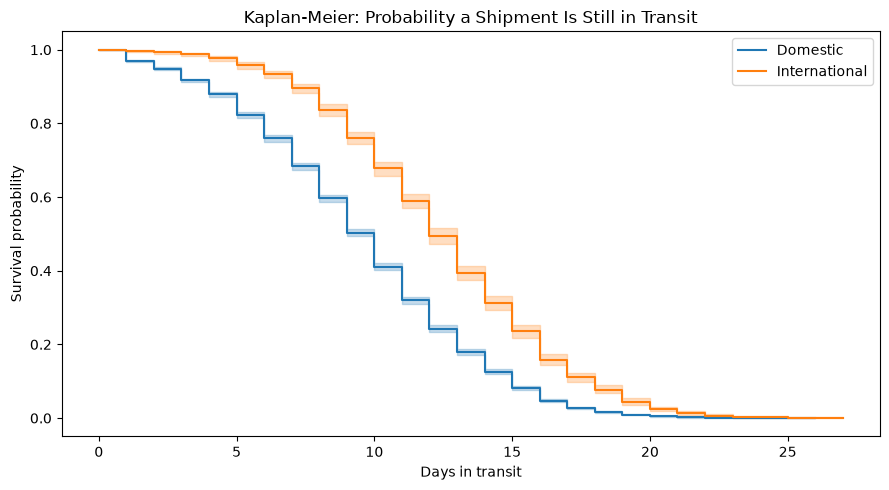

      segment  shipments  median_days  P(still in transit at day 14)  P(still in transit at day 20)
     Domestic      10299         10.0                          0.125                          0.005
International       2287         12.0                          0.313                          0.024


In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test, multivariate_logrank_test

# Days in transit (ship date to delivery)
df["duration"] = df["lead_time_days"]
# Delivery observed for every shipment (no censoring)
df["event"] = 1                                
df["segment"] = np.where(df["destination_region"] == "INTERNATIONAL", "International", "Domestic")

print(f"Shipments: {len(df):,} | Delivered (events): {df['event'].sum():,} | Censored: {(df['event'] == 0).sum()}")

kmf = KaplanMeierFitter()
fig, ax = plt.subplots(figsize=(9, 5))
rows = []

for name, g in df.groupby("segment"):
    kmf.fit(g["duration"], g["event"], label=name)
    kmf.plot_survival_function(ax=ax, ci_show=True)
    rows.append({"segment": name, "shipments": len(g),
                 "median_days": kmf.median_survival_time_,
                 "P(still in transit at day 14)": float(kmf.predict(14)),
                 "P(still in transit at day 20)": float(kmf.predict(20))})

ax.set_title("Kaplan-Meier: Probability a Shipment Is Still in Transit")
ax.set_xlabel("Days in transit")
ax.set_ylabel("Survival probability")
plt.tight_layout()
plt.show()

print(pd.DataFrame(rows).round(3).to_string(index=False))

#### Log-Rank Tests

In [26]:
dom = df[df["segment"] == "Domestic"]
intl = df[df["segment"] == "International"]

res = logrank_test(dom["duration"], intl["duration"], dom["event"], intl["event"])
print(f"Log-rank test: chi-square = {res.test_statistic:.1f}, p-value = {res.p_value:.4g}")

# Extension: compare all four transport modes
multi = multivariate_logrank_test(df["duration"], df["transport_mode"], df["event"])
print(f"Log-rank by transport mode: chi-square = {multi.test_statistic:.1f}, p-value = {multi.p_value:.4g}")

Log-rank test: chi-square = 688.1, p-value = 1.154e-151
Log-rank by transport mode: chi-square = 52.7, p-value = 2.078e-11


**Conclusion and recommendation:** The median transit time is 10 days for domestic shipments and 12 days for international ones, and the log-rank test confirms the difference is highly significant (chi-square = 688, p < 0.001). The tail is where the gap matters most: 31.3% of international shipments are still in transit at day 14, compared with 12.5% of domestic ones. Customer promises and delay alerts for international orders should therefore be set using a longer transit window, and the long-tail shipments (beyond day 14) should be monitored proactively.

### **Business problem:** Before using the lead time model to set delivery promises, its assumptions must hold. Correlated predictors can distort coefficients, unequal error spread can make some predictions less reliable than others, and non-random residuals can signal a missing pattern. These checks confirm whether the multiple regression from the previous step can be trusted.

1. MULTICOLLINEARITY (VIF)
         feature  VIF
       mode_ROAD 1.69
       mode_RAIL 1.64
        mode_SEA 1.53
     distance_km 1.27
is_international 1.19
  order_quantity 1.11
       unit_cost 1.08
       weight_kg 1.04
Max VIF = 1.69 (concern above 5, serious above 10)

2. HETEROSKEDASTICITY
Breusch-Pagan: LM = 21.23, p-value = 0.006557
Residual std by fitted-value quintile:
(0.688, 7.664]      3.199
(7.664, 9.236]      3.261
(9.236, 10.687]     3.289
(10.687, 12.488]    3.328
(12.488, 20.589]    3.171
Max SE difference (classic vs HC3): 2.5%

3. RESIDUAL ANALYSIS
Mean = 0.0000 | Std = 3.250
Skewness = -0.028 | Excess kurtosis = -0.094
Shapiro-Wilk (5,000 sample): W = 0.9996, p-value = 0.3461
Durbin-Watson = 2.019 (about 2 means no autocorrelation)
Max Cook's distance = 0.0025 (concern above 1)

4. PREDICTION METRICS
      Train   Test
MAE   2.602  2.596
RMSE  3.250  3.233
R2    0.432  0.450
Baseline MAE (predict the mean) = 3.487


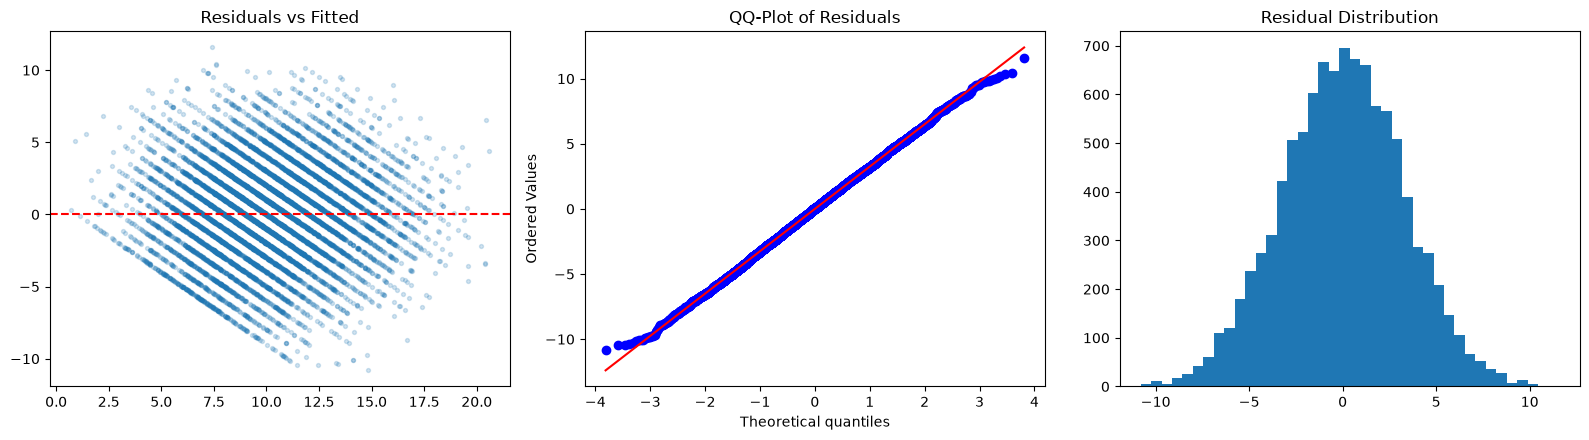

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ---------------- Data and model ----------------
target = "lead_time_days"
df["is_international"] = (df["destination_region"] == "INTERNATIONAL").astype(int)
modes = pd.get_dummies(df["transport_mode"], prefix="mode", drop_first=True).astype(int)
data = pd.concat([df, modes], axis=1)

features = ["distance_km", "unit_cost", "order_quantity", "weight_kg", "is_international"] + list(modes.columns)
X, y = data[features], data[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

X_train_c = sm.add_constant(X_train)
model = sm.OLS(y_train, X_train_c).fit()
resid, fitted = model.resid, model.fittedvalues

line = "=" * 70

# ---------------- 1. Multicollinearity ----------------
print(line, "\n1. MULTICOLLINEARITY (VIF)\n", line, sep="")
vif = pd.DataFrame({"feature": X_train_c.columns,
                    "VIF": [variance_inflation_factor(X_train_c.values, i) for i in range(X_train_c.shape[1])]})
print(vif[vif["feature"] != "const"].sort_values("VIF", ascending=False).round(2).to_string(index=False))
print(f"Max VIF = {vif[vif['feature'] != 'const']['VIF'].max():.2f} (concern above 5, serious above 10)")

# ---------------- 2. Heteroskedasticity ----------------
print("\n", line, "\n2. HETEROSKEDASTICITY\n", line, sep="")
bp = het_breuschpagan(resid, X_train_c)
print(f"Breusch-Pagan: LM = {bp[0]:.2f}, p-value = {bp[1]:.4g}")
quintiles = pd.qcut(fitted, 5)
print("Residual std by fitted-value quintile:")
print(resid.groupby(quintiles, observed=True).std().round(3).to_string())
robust = model.get_robustcov_results(cov_type="HC3")
se_check = pd.DataFrame({"SE_classic": model.bse, "SE_HC3": pd.Series(robust.bse, index=model.params.index)})
print(f"Max SE difference (classic vs HC3): {(se_check['SE_HC3'] / se_check['SE_classic'] - 1).abs().max():.1%}")

# ---------------- 3. Residual analysis ----------------
print("\n", line, "\n3. RESIDUAL ANALYSIS\n", line, sep="")
print(f"Mean = {resid.mean():.4f} | Std = {resid.std():.3f}")
print(f"Skewness = {stats.skew(resid):.3f} | Excess kurtosis = {stats.kurtosis(resid):.3f}")
sh = stats.shapiro(resid.sample(5000, random_state=42))
print(f"Shapiro-Wilk (5,000 sample): W = {sh.statistic:.4f}, p-value = {sh.pvalue:.4f}")
print(f"Durbin-Watson = {durbin_watson(resid):.3f} (about 2 means no autocorrelation)")
print(f"Max Cook's distance = {model.get_influence().cooks_distance[0].max():.4f} (concern above 1)")

# ---------------- 4. Prediction metrics ----------------
print("\n", line, "\n4. PREDICTION METRICS\n", line, sep="")
pred_test = model.predict(sm.add_constant(X_test, has_constant="add"))
sets = {"Train": (y_train, fitted), "Test": (y_test, pred_test)}
metrics = pd.DataFrame({n: {"MAE": mean_absolute_error(a, p),
                            "RMSE": np.sqrt(mean_squared_error(a, p)),
                            "R2": r2_score(a, p)} for n, (a, p) in sets.items()})
print(metrics.round(3))
print(f"Baseline MAE (predict the mean) = {mean_absolute_error(y_test, np.full(len(y_test), y_train.mean())):.3f}")

# ---------------- Plots ----------------
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ax[0].scatter(fitted, resid, alpha=0.2, s=8)
ax[0].axhline(0, color="red", linestyle="--")
ax[0].set_title("Residuals vs Fitted")
stats.probplot(resid, dist="norm", plot=ax[1])
ax[1].set_title("QQ-Plot of Residuals")
ax[2].hist(resid, bins=40)
ax[2].set_title("Residual Distribution")
plt.tight_layout()
plt.show()

**Conclusion and recommendation:** All VIF values are below 2, so multicollinearity is not a concern, and the Breusch-Pagan test (p = 0.007) detects heteroskedasticity that is practically negligible, since residual spread is nearly constant (3.17 to 3.33 across fitted quintiles) and robust standard errors match the classic ones. Residuals are centered at zero, approximately normal (skewness -0.03, Shapiro-Wilk p = 0.35), uncorrelated (Durbin-Watson = 2.02), and free of influential points (max Cook’s distance 0.0025), while train and test metrics are nearly identical (MAE 2.60 vs. 2.60), so the model is valid and not overfit. The model can be used for lead time estimates, but since it explains only 43% to 45% of the variation, delivery promises should include a buffer and additional predictors should be explored.

### **Business problem:** Delivery promises are only as good as the lead time estimates behind them. Planners need to predict transit lead time (lead_time_days) from shipment characteristics, and want to know how much accuracy is gained by moving from a single predictor (distance) to a model that also uses order value, size, weight, destination, and transport mode.

        Simple (distance_km)  Multiple
MAE                    3.124     2.596
MSE                   15.129    10.454
RMSE                   3.890     3.233
R2                     0.204     0.450
Adj R2                 0.204     0.448
Baseline MAE (predict the mean): 3.487


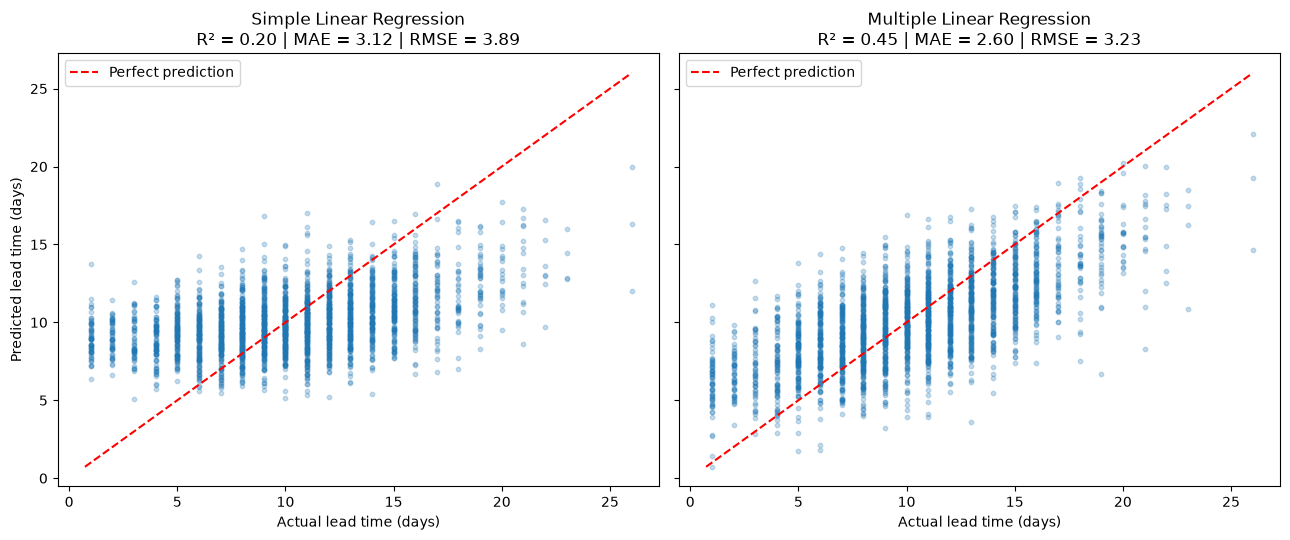

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

target = "lead_time_days"

df["is_international"] = (df["destination_region"] == "INTERNATIONAL").astype(int)
modes = pd.get_dummies(df["transport_mode"], prefix="mode", drop_first=True).astype(int)   # AIR is the reference
data = pd.concat([df, modes], axis=1)

simple_features = ["distance_km"]
multi_features = ["distance_km", "unit_cost", "order_quantity", "weight_kg", "is_international"] + list(modes.columns)

y = data[target]
idx_train, idx_test = train_test_split(data.index, test_size=0.2, random_state=42)

def fit_eval(features):
    model = LinearRegression().fit(data.loc[idx_train, features], y.loc[idx_train])
    pred = model.predict(data.loc[idx_test, features])
    actual = y.loc[idx_test]
    n, k = len(actual), len(features)
    r2 = r2_score(actual, pred)
    metrics = {
        "MAE": mean_absolute_error(actual, pred),
        "MSE": mean_squared_error(actual, pred),
        "RMSE": np.sqrt(mean_squared_error(actual, pred)),
        "R2": r2,
        "Adj R2": 1 - (1 - r2) * (n - 1) / (n - k - 1),
    }
    return model, pred, actual, metrics

m1, p1, a1, met1 = fit_eval(simple_features)
m2, p2, a2, met2 = fit_eval(multi_features)

# Baseline: always predict the training mean
baseline_mae = mean_absolute_error(a1, np.full(len(a1), y.loc[idx_train].mean()))

print(pd.DataFrame({"Simple (distance_km)": met1, "Multiple": met2}).round(3))
print(f"Baseline MAE (predict the mean): {baseline_mae:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharex=True, sharey=True)
lims = [min(a1.min(), p1.min(), p2.min()), max(a1.max(), p1.max(), p2.max())]

for ax, pred, actual, title, met in [
    (axes[0], p1, a1, "Simple Linear Regression", met1),
    (axes[1], p2, a2, "Multiple Linear Regression", met2),
]:
    ax.scatter(actual, pred, alpha=0.25, s=10)
    ax.plot(lims, lims, "r--", label="Perfect prediction")
    ax.set_title(f"{title}\nR² = {met['R2']:.2f} | MAE = {met['MAE']:.2f} | RMSE = {met['RMSE']:.2f}")
    ax.set_xlabel("Actual lead time (days)")
    ax.legend()

axes[0].set_ylabel("Predicted lead time (days)")
plt.tight_layout()
plt.show()

**Conclusion and recommendation:** Distance alone explains only 20% of lead time variation (R² = 0.20, MAE = 3.12 days), while the multiple model explains 45% (R² = 0.45, MAE = 2.60, RMSE = 3.23), reducing the average error by about 25% compared with the baseline MAE of 3.49 days. Order unit cost is the strongest driver (about 0.22 fewer days per one-unit increase), international destinations add about 0.8 days, and each additional 100 km adds about 0.8 days. Planners should use the multiple model to set promise dates, but because more than half of the variation remains unexplained, they should add a buffer and test additional predictors before relying on it for tight commitments.

### **Business problem:** Shipment damage drives claims, returns, and customer complaints, and about 11.7% of shipments arrive damaged. If the damage risk could be predicted before dispatch, high-risk shipments could receive extra packaging or a more careful carrier. The goal is to compare an interpretable model (logistic regression) with a more flexible one (random forest) on their ability to identify damaged shipments, using only information known at dispatch.

Damage rate: train = 11.74%, test = 11.76%
                     Accuracy  Precision  Recall     F1  ROC-AUC
Model                                                           
Logistic Regression     0.736      0.262   0.686  0.379    0.784
Random Forest           0.763      0.281   0.652  0.393    0.785
Baseline accuracy (always predict 'no damage'): 0.882


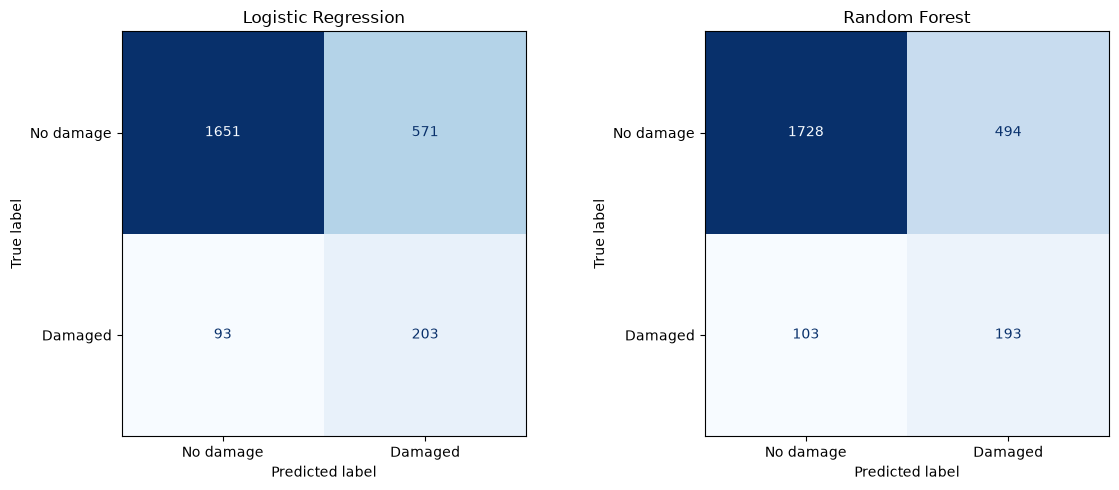

In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score,
                             precision_score, recall_score, f1_score, roc_auc_score)

target = "damage_flag"
df["is_international"] = (df["destination_region"] == "INTERNATIONAL").astype(int)
modes = pd.get_dummies(df["transport_mode"], prefix="mode", drop_first=True).astype(int)
data = pd.concat([df, modes], axis=1)

features = ["distance_km", "unit_cost", "order_quantity", "weight_kg", "is_international"] + list(modes.columns)
X, y = data[features], data[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print(f"Damage rate: train = {y_train.mean():.2%}, test = {y_test.mean():.2%}")

models = {
    "Logistic Regression": make_pipeline(StandardScaler(),
                                         LogisticRegression(class_weight="balanced", max_iter=1000)),
    "Random Forest": RandomForestClassifier(n_estimators=3000, max_depth=8, min_samples_leaf=20,
                                            class_weight="balanced", random_state=42, n_jobs=-1),
}

rows, fitted = [], {}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    fitted[name] = (model, pred)
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(y_test, pred),
                 "Precision": precision_score(y_test, pred),
                 "Recall": recall_score(y_test, pred),
                 "F1": f1_score(y_test, pred),
                 "ROC-AUC": roc_auc_score(y_test, proba)})

print(pd.DataFrame(rows).set_index("Model").round(3))
print(f"Baseline accuracy (always predict 'no damage'): {1 - y_test.mean():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, (model, pred)) in zip(axes, fitted.items()):
    cm = confusion_matrix(y_test, pred)
    ConfusionMatrixDisplay(cm, display_labels=["No damage", "Damaged"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)

plt.tight_layout()
plt.show()

**Conclusion and recommendation:** Both models perform similarly (ROC-AUC of 0.78), with logistic regression catching more damaged shipments (recall 0.69, 203 of 296) and the random forest being slightly more precise (precision 0.28 vs. 0.26) and accurate (0.76 vs. 0.74). Distance, international destination, and low unit cost are the main risk drivers in both models, and the precision of only about 27% reflects how rare damage is, so most flagged shipments will not actually be damaged. Because the simpler logistic regression matches the random forest and is easy to explain, it is the better choice for flagging high-risk shipments, with the decision threshold tuned to balance the cost of extra packaging against the cost of damage.

### **Business problem:** The earlier models (logistic regression and random forest) predicted shipment damage with a ROC-AUC of about 0.78. The question is whether more advanced methods can find patterns that those models missed. Gradient boosting builds many small trees that correct each other’s errors, and the SVM draws a flexible non-linear boundary between damaged and undamaged shipments. Both use the same features and the same test set, so the comparison is fair and the results are printed in a single output.

           Accuracy  Precision  Recall     F1  ROC-AUC   TP   FN   FP    TN
Model                                                                      
XGBoost       0.750      0.268   0.652  0.380    0.776  193  103  526  1696
SVM (RBF)     0.754      0.273   0.659  0.386    0.763  195  101  519  1703
Baseline accuracy (always 'no damage'): 0.882

XGBoost feature importance:
is_international    0.445
distance_km         0.200
unit_cost           0.085
mode_SEA            0.061
mode_RAIL           0.060
order_quantity      0.055
weight_kg           0.052
mode_ROAD           0.043


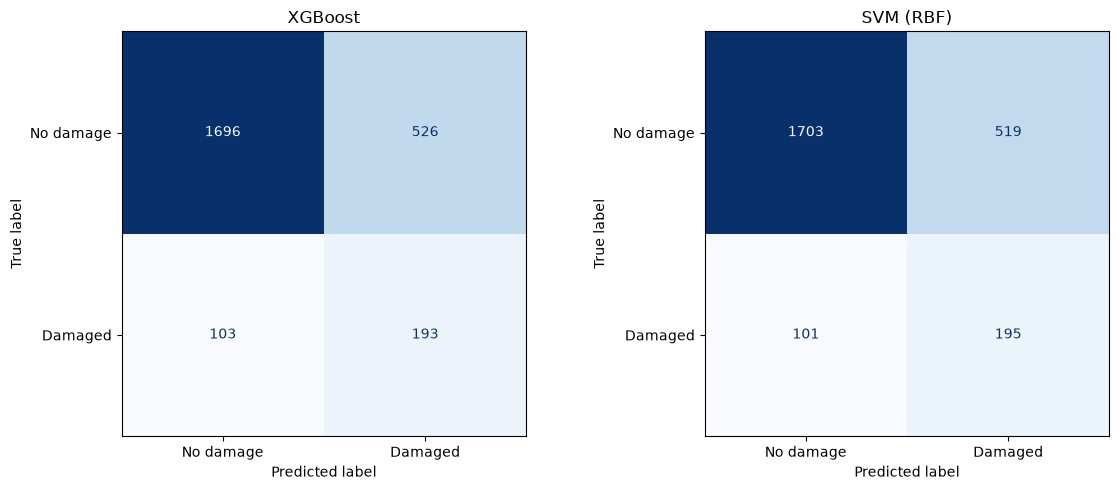

In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score,
                             precision_score, recall_score, f1_score, roc_auc_score)

# ---------------- Data ----------------
target = "damage_flag"
df["is_international"] = (df["destination_region"] == "INTERNATIONAL").astype(int)
modes = pd.get_dummies(df["transport_mode"], prefix="mode", drop_first=True).astype(int)
data = pd.concat([df, modes], axis=1)

features = ["distance_km", "unit_cost", "order_quantity", "weight_kg", "is_international"] + list(modes.columns)
X, y = data[features], data[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)


pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

models = {
    "XGBoost": XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8,
                             colsample_bytree=0.8, scale_pos_weight=pos_weight,
                             eval_metric="logloss", random_state=42, n_jobs=-1),
    "SVM (RBF)": make_pipeline(StandardScaler(),
                               SVC(kernel="rbf", C=1.0, class_weight="balanced")),
}

# ---------------- Train, predict, evaluate ----------------
rows, fitted = [], {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    score = model.predict_proba(X_test)[:, 1] if name == "XGBoost" else model.decision_function(X_test)
    cm = confusion_matrix(y_test, pred)
    fitted[name] = (model, pred, cm)
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(y_test, pred),
                 "Precision": precision_score(y_test, pred),
                 "Recall": recall_score(y_test, pred),
                 "F1": f1_score(y_test, pred),
                 "ROC-AUC": roc_auc_score(y_test, score),
                 "TP": cm[1, 1], "FN": cm[1, 0], "FP": cm[0, 1], "TN": cm[0, 0]})

# ---------------- One combined result ----------------
results = pd.DataFrame(rows).set_index("Model")
print(results.round(3).to_string())
print(f"Baseline accuracy (always 'no damage'): {1 - y_test.mean():.3f}")

imp = pd.Series(fitted["XGBoost"][0].feature_importances_, index=features).sort_values(ascending=False)
print("\nXGBoost feature importance:")
print(imp.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, (m, pred, cm)) in zip(axes, fitted.items()):
    ConfusionMatrixDisplay(cm, display_labels=["No damage", "Damaged"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

**Conclusion and recommendation:** The SVM and XGBoost perform almost identically (recall of 0.66 vs. 0.65, precision of 0.27 vs. 0.26, ROC-AUC of 0.76 vs. 0.77), and neither improves on the simpler logistic regression and random forest from the previous step (ROC-AUC of 0.78). XGBoost ranks international destination (0.46) and distance (0.19) as the dominant drivers, which confirms that the predictive signal is concentrated in a few variables and that more complex models cannot extract more from the same features. The team should keep the logistic regression for interpretability and instead invest in new predictors, such as packaging type, product category, or carrier handling data, to improve damage prediction.

### **Business problem:** Replenishment and warehouse staffing depend on knowing how many units customers will order each day. Planners need to know whether daily demand follows a forecastable pattern (trend, weekly seasonality, autocorrelation), and whether SARIMA or Holt-Winters can predict the next 60 days better than a simple average. Both models are compared against two naive baselines on the same hold-out period.

Daily demand: 365 days | mean = 1,426 | std = 331
ADF test p-value = 2.765e-29 -> stationary
Best SARIMA(0, 0, 0)x(0, 0, 0, 7) | AIC = 4396.7
                                 MAE    RMSE  MAPE (%)
Mean baseline                 292.66  359.43     24.52
Seasonal naive                364.73  464.45     31.28
SARIMA(0, 0, 0)x(0, 0, 0, 7)  292.66  359.43     24.52
Holt-Winters                  289.20  351.86     24.12
Holt-Winters: alpha = 0.000, gamma = 0.000


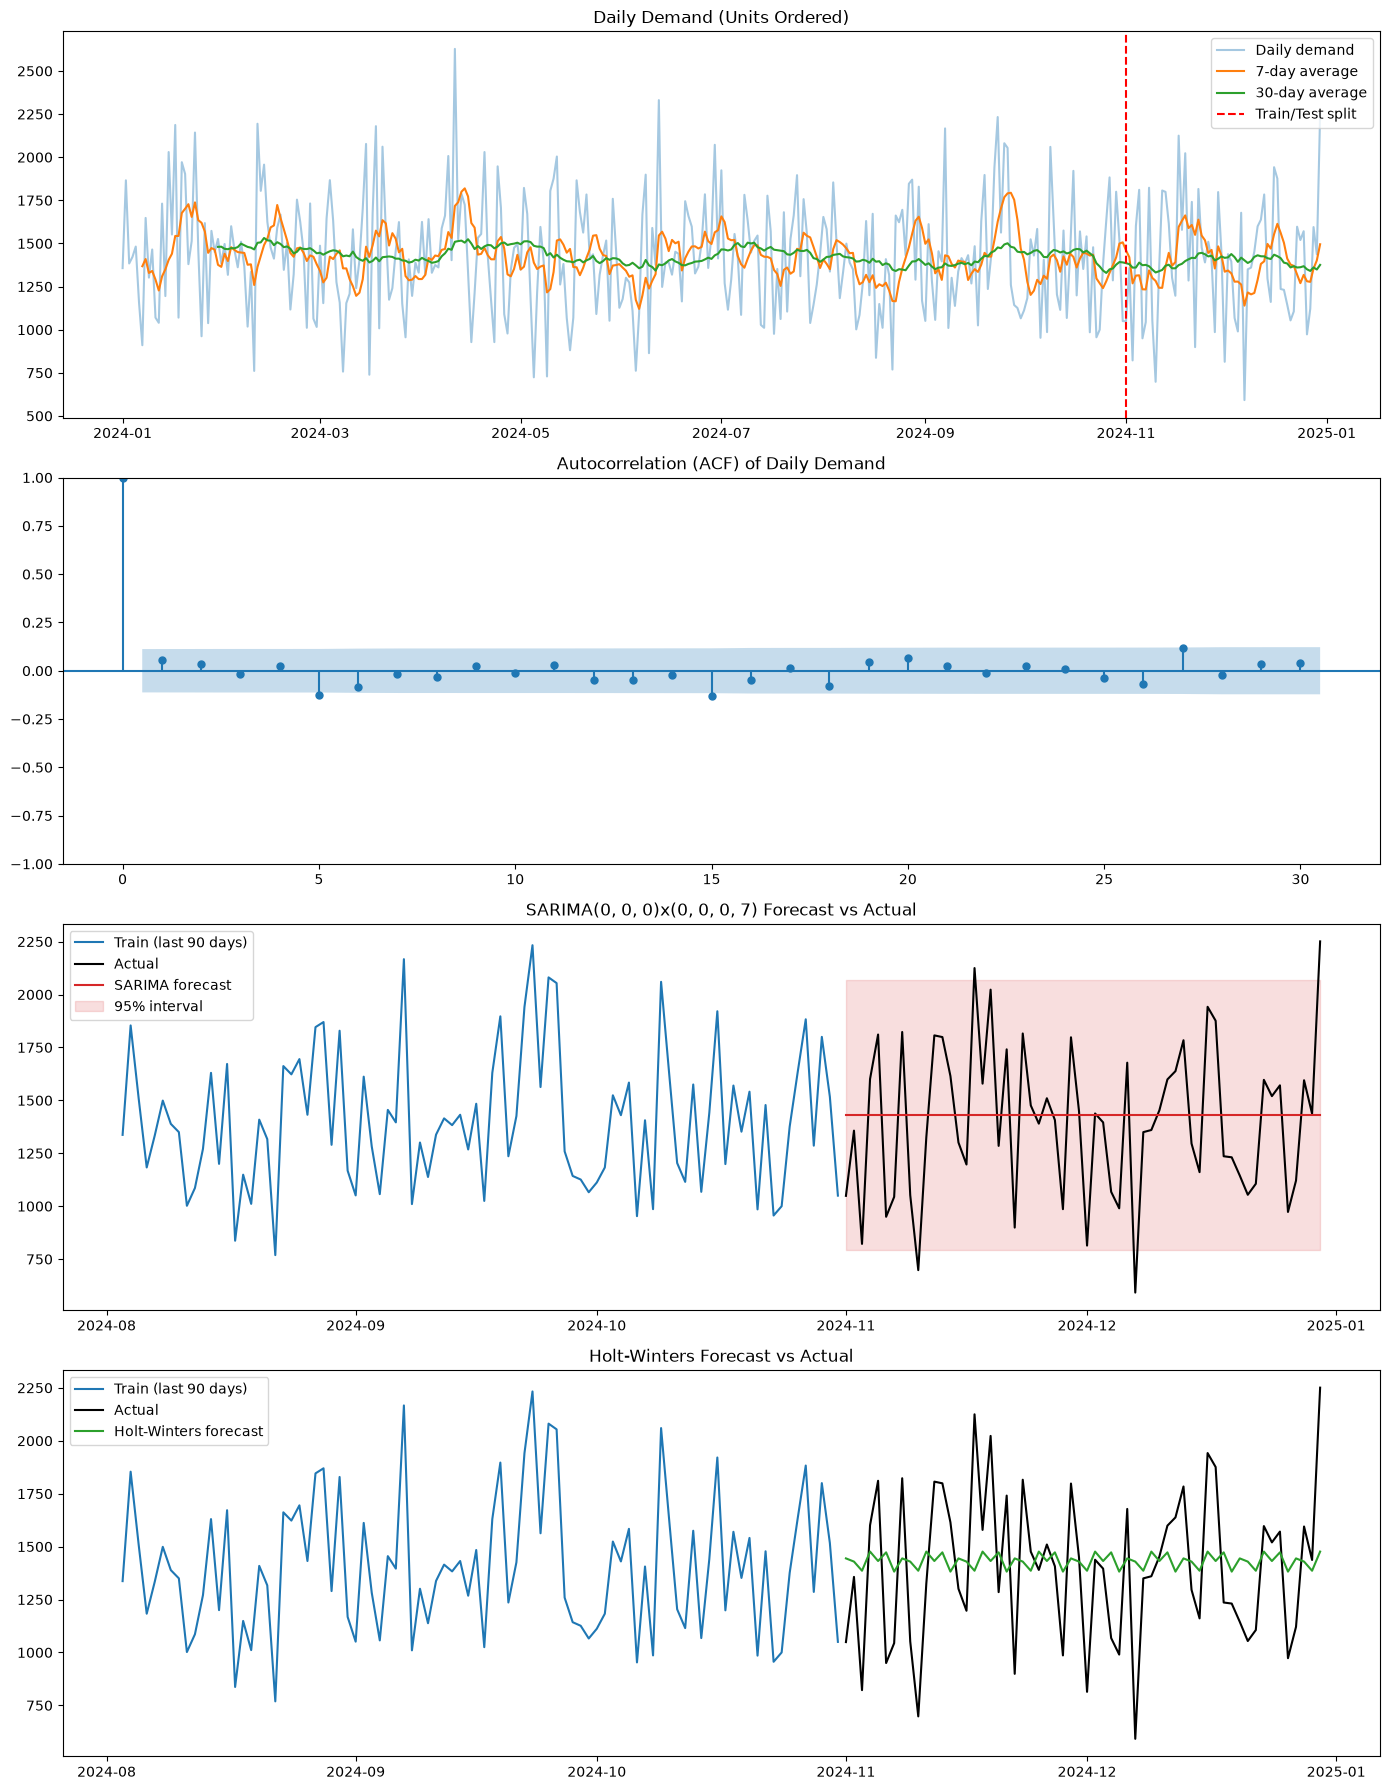

In [31]:
import warnings, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tools.sm_exceptions import ConvergenceWarning
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.simplefilter("ignore", ConvergenceWarning)
warnings.simplefilter("ignore", FutureWarning)

# ---------------- Daily demand (units ordered per day) ----------------
df["order_date"] = pd.to_datetime(df["order_date"])
demand = df.groupby("order_date")["order_quantity"].sum().asfreq("D").fillna(0)

H = 60                                   # forecast horizon: last 60 days
train, test = demand.iloc[:-H], demand.iloc[-H:]

adf_p = adfuller(train, regression="c")[1]
print(f"Daily demand: {len(demand)} days | mean = {demand.mean():,.0f} | std = {demand.std():,.0f}")
print(f"ADF test p-value = {adf_p:.4g} -> {'stationary' if adf_p < 0.05 else 'non-stationary'}")

# ---------------- SARIMA: grid search by AIC (weekly seasonality, period = 7) ----------------
best = None
for p, q, P, Q in itertools.product([0, 1, 2], [0, 1, 2], [0, 1], [0, 1]):
    try:
        res = SARIMAX(train, order=(p, 0, q), seasonal_order=(P, 0, Q, 7), trend="c").fit(disp=False)
        if best is None or res.aic < best[0]:
            best = (res.aic, (p, 0, q), (P, 0, Q, 7), res)
    except Exception:
        pass

aic, order, sorder, sarima = best
print(f"Best SARIMA{order}x{sorder} | AIC = {aic:.1f}")

fc = sarima.get_forecast(H)
sarima_pred, sarima_ci = fc.predicted_mean, fc.conf_int()

# ---------------- Holt-Winters ----------------
hw = ExponentialSmoothing(train, trend="add", damped_trend=True,
                          seasonal="add", seasonal_periods=7).fit()
hw_pred = hw.forecast(H)

# ---------------- Baselines ----------------
mean_pred = pd.Series(train.mean(), index=test.index)
snaive_pred = pd.Series(np.tile(train.iloc[-7:].values, H // 7 + 1)[:H], index=test.index)

# ---------------- Metrics ----------------
def metrics(actual, pred):
    return {"MAE": mean_absolute_error(actual, pred),
            "RMSE": np.sqrt(mean_squared_error(actual, pred)),
            "MAPE (%)": np.mean(np.abs((actual - pred) / actual)) * 100}

results = pd.DataFrame({
    "Mean baseline": metrics(test, mean_pred),
    "Seasonal naive": metrics(test, snaive_pred),
    f"SARIMA{order}x{sorder}": metrics(test, sarima_pred),
    "Holt-Winters": metrics(test, hw_pred),
}).T
print(results.round(2).to_string())
print(f"Holt-Winters: alpha = {hw.params['smoothing_level']:.3f}, gamma = {hw.params['smoothing_seasonal']:.3f}")

# ---------------- Visuals: wide rectangles, stacked vertically ----------------
fig, ax = plt.subplots(4, 1, figsize=(14, 18))

ax[0].plot(demand, alpha=0.4, label="Daily demand")
ax[0].plot(demand.rolling(7).mean(), label="7-day average")
ax[0].plot(demand.rolling(30).mean(), label="30-day average")
ax[0].axvline(test.index[0], color="red", linestyle="--", label="Train/Test split")
ax[0].set_title("Daily Demand (Units Ordered)")
ax[0].legend()

plot_acf(train, lags=30, ax=ax[1])
ax[1].set_title("Autocorrelation (ACF) of Daily Demand")

ax[2].plot(train.iloc[-90:], label="Train (last 90 days)")
ax[2].plot(test, color="black", label="Actual")
ax[2].plot(sarima_pred, color="tab:red", label="SARIMA forecast")
ax[2].fill_between(test.index, sarima_ci.iloc[:, 0], sarima_ci.iloc[:, 1],
                   color="tab:red", alpha=0.15, label="95% interval")
ax[2].set_title(f"SARIMA{order}x{sorder} Forecast vs Actual")
ax[2].legend()

ax[3].plot(train.iloc[-90:], label="Train (last 90 days)")
ax[3].plot(test, color="black", label="Actual")
ax[3].plot(hw_pred, color="tab:green", label="Holt-Winters forecast")
ax[3].set_title("Holt-Winters Forecast vs Actual")
ax[3].legend()

plt.tight_layout()
plt.show()

**Conclusion and recommendation:** Daily demand is stationary (ADF p < 0.001) with no meaningful autocorrelation, so the AIC search selects SARIMA(0,0,0)x(0,0,0,7), which is equivalent to forecasting the historical mean (MAE = 292.7 units, MAPE = 24.5%), and Holt-Winters improves on it only marginally (MAE = 288.9) with smoothing parameters near zero. The seasonal naive baseline performs worst (MAE = 364.7), confirming that there is no stable weekly pattern to exploit and that day-to-day variation is essentially random around 1,426 units. Planners should size inventory and staffing on the average demand plus a safety buffer based on its standard deviation (about 330 units per day), and look for external drivers such as promotions or holidays before investing in more complex forecasting.

### **Business problem:** Operations must know whether service quality is stable and whether the process can meet its targets. The p-chart monitors the daily damage rate, the c-chart monitors the daily count of late deliveries, the EWMA chart detects small sustained shifts in processing time, and the capability indices (Cp and Cpk) measure whether processing time can consistently meet the 2-day SLA.

1. p-CHART: DAILY DAMAGE RATE
Center line (p-bar) = 11.74% | days = 365 | out-of-control days = 1
             n  damaged      p    ucl
order_date                           
2024-10-07  35       11  0.314  0.281

2. c-CHART: LATE DELIVERIES PER DAY
Center line (c-bar) = 2.95 | UCL = 8.10 | LCL = 0.00 | out-of-control days = 4
2024-07-23    10
2024-08-07     9
2024-08-21    10
2024-10-15     9

3. EWMA CHART: DAILY MEAN PROCESSING TIME
Target (mean) = 2.51 days | lambda = 0.2 | L = 3 | out-of-control days = 0

4. PROCESS CAPABILITY: PROCESSING TIME
Mean = 2.51 | Std = 1.71 | USL = 2 days
Cp = 0.20 | Cpk = -0.10 | Share above USL = 50.1% | Observed DPMO = 500,715


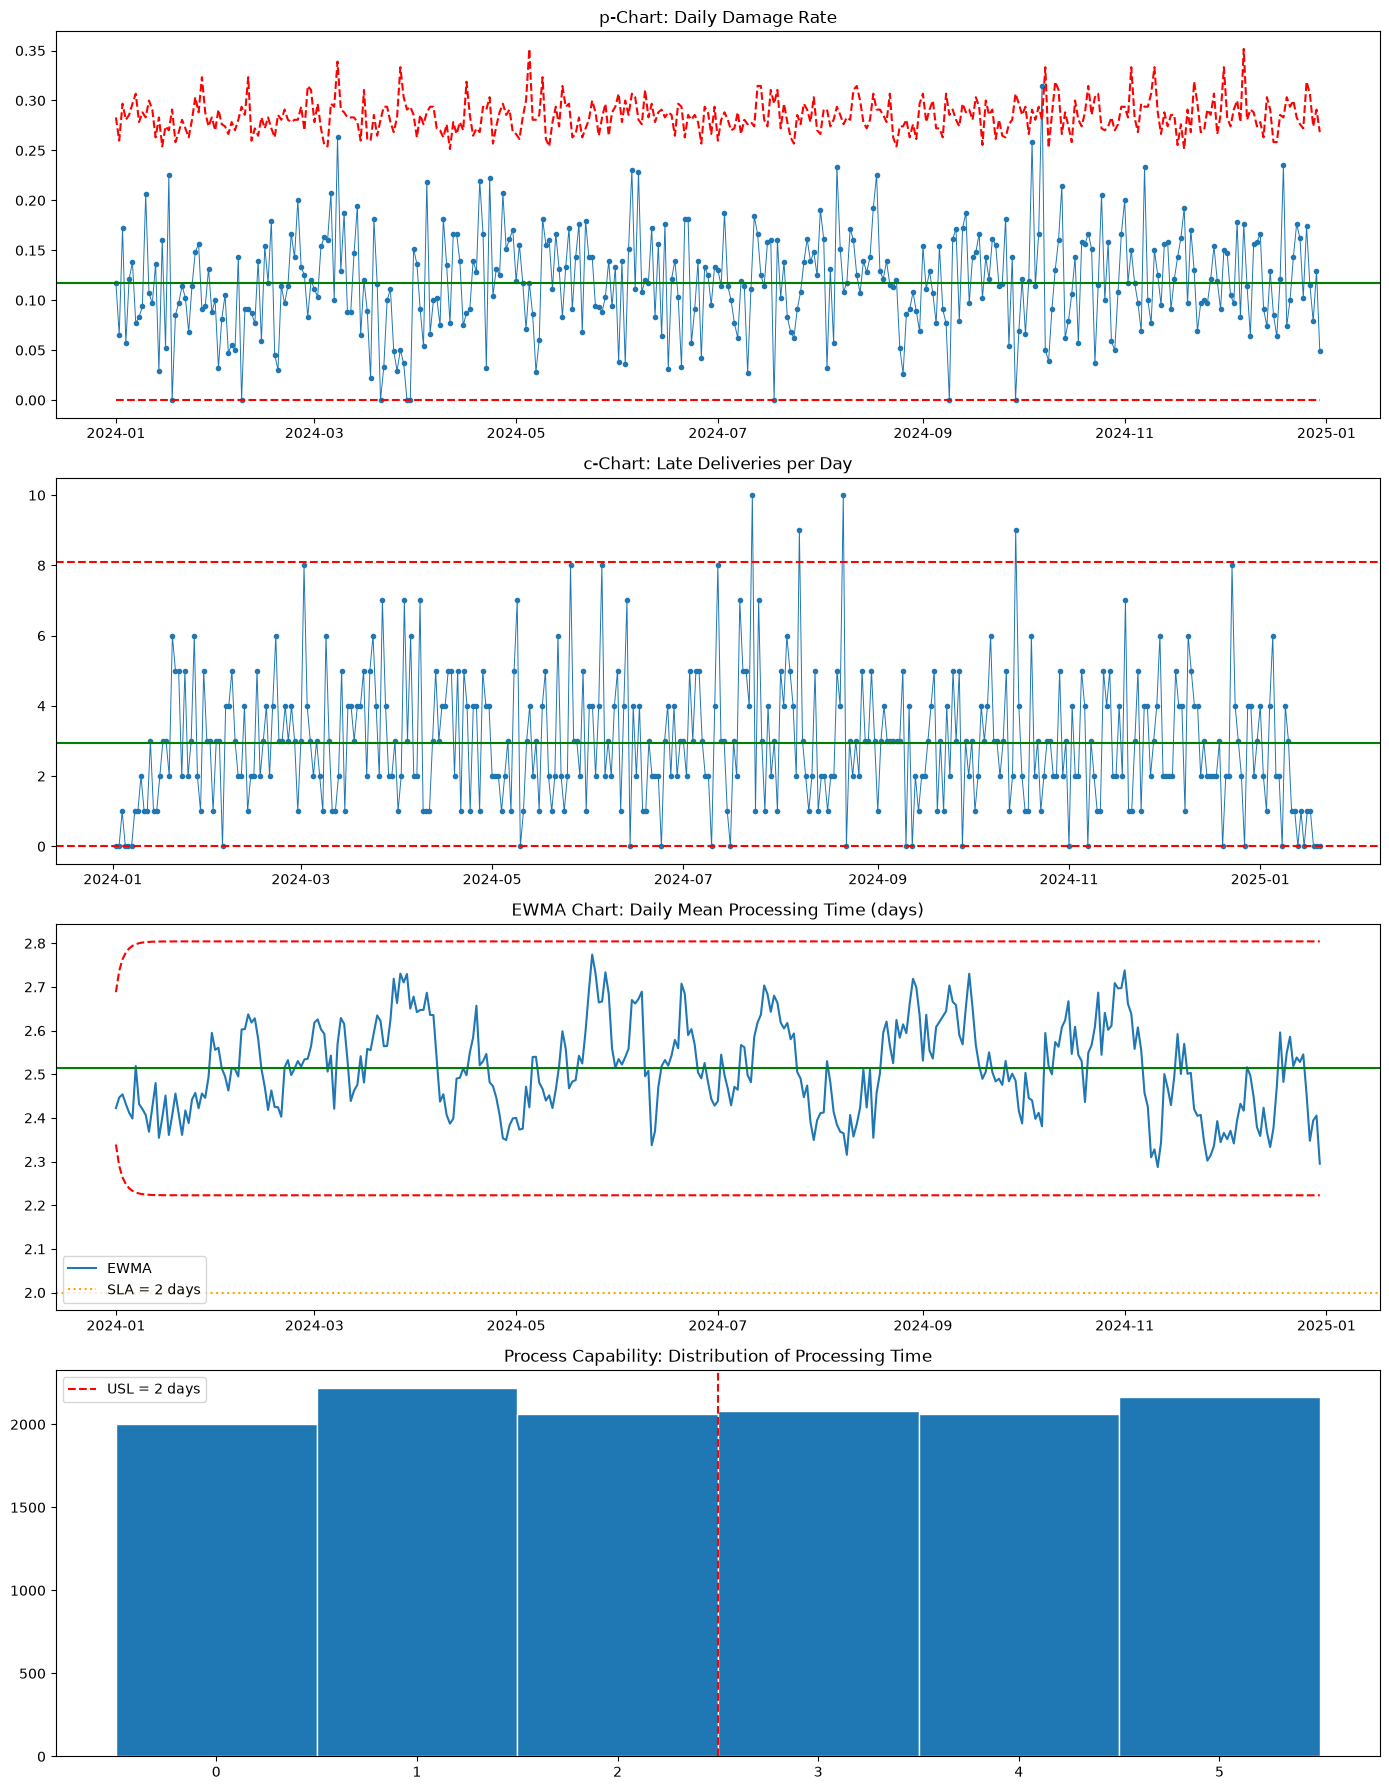

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

for col in ["order_date", "ship_date", "actual_delivery_date"]:
    df[col] = pd.to_datetime(df[col])
df["processing_days"] = (df["ship_date"] - df["order_date"]).dt.days
df["is_late"] = (df["delay_days"] > 0).astype(int)

line = "=" * 70

# ---------- 1. p-chart: daily damage rate (variable subgroup size) ----------
print(line, "\n1. p-CHART: DAILY DAMAGE RATE\n", line, sep="")
daily = df.groupby("order_date")["damage_flag"].agg(damaged="sum", n="count")
daily["p"] = daily["damaged"] / daily["n"]
p_bar = daily["damaged"].sum() / daily["n"].sum()
daily["ucl"] = p_bar + 3 * np.sqrt(p_bar * (1 - p_bar) / daily["n"])
daily["lcl"] = (p_bar - 3 * np.sqrt(p_bar * (1 - p_bar) / daily["n"])).clip(lower=0)
out_p = daily[(daily["p"] > daily["ucl"]) | (daily["p"] < daily["lcl"])]
print(f"Center line (p-bar) = {p_bar:.2%} | days = {len(daily)} | out-of-control days = {len(out_p)}")
if len(out_p):
    print(out_p[["n", "damaged", "p", "ucl"]].round(3).to_string())

# ---------- 2. c-chart: late deliveries per day ----------
print("\n", line, "\n2. c-CHART: LATE DELIVERIES PER DAY\n", line, sep="")
days = pd.date_range(df["actual_delivery_date"].min(), df["actual_delivery_date"].max())
c = df.groupby("actual_delivery_date")["is_late"].sum().reindex(days, fill_value=0)
c_bar = c.mean()
ucl_c, lcl_c = c_bar + 3 * np.sqrt(c_bar), max(c_bar - 3 * np.sqrt(c_bar), 0)
out_c = c[(c > ucl_c) | (c < lcl_c)]
print(f"Center line (c-bar) = {c_bar:.2f} | UCL = {ucl_c:.2f} | LCL = {lcl_c:.2f} | out-of-control days = {len(out_c)}")
if len(out_c):
    print(out_c.to_string())

# ---------- 3. EWMA chart: small shifts in daily mean processing time ----------
print("\n", line, "\n3. EWMA CHART: DAILY MEAN PROCESSING TIME\n", line, sep="")
x = df.groupby("order_date")["processing_days"].mean()
mu, sigma = df["processing_days"].mean(), df["processing_days"].std()
n_day = df.groupby("order_date").size()
lam, L = 0.2, 3

z, prev = [], mu                       # EWMA starts at the target (process mean)
for val in x.values:
    prev = lam * val + (1 - lam) * prev
    z.append(prev)
ewma = pd.Series(z, index=x.index)

i = np.arange(1, len(x) + 1)
sd = sigma / np.sqrt(n_day.mean()) * np.sqrt(lam / (2 - lam) * (1 - (1 - lam) ** (2 * i)))
ucl_e, lcl_e = mu + L * sd, mu - L * sd
out_e = ewma[(ewma.values > ucl_e) | (ewma.values < lcl_e)]
print(f"Target (mean) = {mu:.2f} days | lambda = {lam} | L = {L} | out-of-control days = {len(out_e)}")

# ---------- 4. Process capability: processing time vs 2-day SLA ----------
print("\n", line, "\n4. PROCESS CAPABILITY: PROCESSING TIME\n", line, sep="")
USL, LSL = 2, 0
v = df["processing_days"]
cp = (USL - LSL) / (6 * v.std())
cpu, cpl = (USL - v.mean()) / (3 * v.std()), (v.mean() - LSL) / (3 * v.std())
cpk = min(cpu, cpl)
print(f"Mean = {v.mean():.2f} | Std = {v.std():.2f} | USL = {USL} days")
print(f"Cp = {cp:.2f} | Cpk = {cpk:.2f} | Share above USL = {(v > USL).mean():.1%} | "
      f"Observed DPMO = {(v > USL).mean() * 1e6:,.0f}")

# ---------- Visuals: wide rectangles, stacked vertically ----------
fig, ax = plt.subplots(4, 1, figsize=(14, 18))

ax[0].plot(daily.index, daily["p"], marker="o", markersize=3, linewidth=0.7)
ax[0].plot(daily.index, daily["ucl"], color="red", linestyle="--")
ax[0].plot(daily.index, daily["lcl"], color="red", linestyle="--")
ax[0].axhline(p_bar, color="green")
ax[0].set_title("p-Chart: Daily Damage Rate")

ax[1].plot(c.index, c.values, marker="o", markersize=3, linewidth=0.7)
ax[1].axhline(c_bar, color="green")
ax[1].axhline(ucl_c, color="red", linestyle="--")
ax[1].axhline(lcl_c, color="red", linestyle="--")
ax[1].set_title("c-Chart: Late Deliveries per Day")

ax[2].plot(ewma.index, ewma.values, label="EWMA")
ax[2].plot(ewma.index, ucl_e, color="red", linestyle="--")
ax[2].plot(ewma.index, lcl_e, color="red", linestyle="--")
ax[2].axhline(mu, color="green")
ax[2].axhline(USL, color="orange", linestyle=":", label="SLA = 2 days")
ax[2].set_title("EWMA Chart: Daily Mean Processing Time (days)")
ax[2].legend()

ax[3].hist(v, bins=np.arange(-0.5, 6.5, 1), edgecolor="white")
ax[3].axvline(USL + 0.5, color="red", linestyle="--", label="USL = 2 days")
ax[3].set_title("Process Capability: Distribution of Processing Time")
ax[3].legend()

plt.tight_layout()
plt.show()

**Conclusion and recommendation:** Damage and late deliveries are statistically stable, with only one out-of-control day on the p-chart (Oct 7: 31.4% vs. a 28.1% limit), four isolated high days on the c-chart (9 to 10 late deliveries vs. an upper limit of 8.1), and no signals on the EWMA chart, so there are no sustained shifts. However, the process is not capable of meeting the SLA (Cp = 0.20, Cpk = -0.10), with 50.1% of shipments above the 2-day limit (about 500,715 defects per million). The isolated signals should be reviewed as one-off events, while the real improvement effort should go into redesigning order processing so that both the average and the spread of processing time fall within the SLA.